# 10 — Deep Learning for DNA Sequence Classification

### Recognizing splice junctions with one-dimensional convolutional networks

**Learning path:** `Deep Learning / Keras`  
**Notebook:** 10 of 12  
**Level:** Advanced  
**Primary tools:** Python, NumPy, pandas, Matplotlib, Keras 3  
**Dataset:** UCI *Molecular Biology (Splice-junction Gene Sequences)* — 3,190 primate DNA windows of 60 nucleotides

---

## Learning objectives

By the end of this notebook, you should be able to:

1. Explain **splicing**, exons, introns, and the **donor** and **acceptor** sites, including the canonical GT…AG rule, and describe what the 60-nucleotide windows of the dataset contain.
2. Encode DNA with **one-hot vectors** (including soft encodings of ambiguity codes) and explain why integer coding is a poor choice; show that an `Embedding` layer equals a one-hot Dense layer.
3. Build **position frequency matrices**, **sequence logos**, and **information content**; derive a **position weight matrix (PWM)** classifier (position-specific naive Bayes) and use it as the classical baseline.
4. Define the **1D convolution** for sequences, derive its output size and parameter count, and prove and verify that **scanning a PWM along a sequence is a 1D convolution** with the PWM as kernel.
5. Choose between **global max pooling** (position-independent motif detection) and **Flatten** (position-aware) for a problem in which the position matters, and justify the choice.
6. Verify our NumPy 1D convolution and its **backward pass** against Keras and a numerical gradient check.
7. Train and compare an MLP and two 1D CNNs with **multiple seeds**, form an **ensemble**, and evaluate it with confusion matrices, per-class metrics, one-vs-rest AUC, intervals, and a paired test against the PWM baseline.
8. Demonstrate **leakage between related sequences** by comparing a random split with a split that keeps genes together.
9. Look inside the network: learned **filters as motifs** and **in-silico mutagenesis** (the effect of every possible point mutation), and check them against known splice-site biology.

> **What is new compared with Notebooks 08–09?** The input is now a *sequence*: a one-dimensional grid with four channels (A, C, G, T). The same ideas apply (local filters, parameter sharing, pooling), but the biological meaning of a filter is much more direct: **a convolution filter on one-hot DNA is a motif detector**. We show this exactly, and then use it to interpret a trained network. The evaluation habits of Notebook 07 are applied to *related* sequences (genes, homologues), the sequence analogue of "same patient" and "same plant".

## 1. The biological problem

A **gene** is first copied into a precursor messenger RNA (pre-mRNA) that contains both the parts that will be kept and the parts that will be removed:

- **Exons** are the parts retained in the mature mRNA (and mostly coding for protein);
- **Introns** are the parts **spliced out** by the spliceosome before the mRNA is translated.

The cell must find the exact boundaries. The two boundaries of an intron are called

| Boundary | Direction (5′→3′) | Name | Dataset label | Canonical signal |
|---|---|---|---|---|
| **exon → intron** | start of the intron | **donor** (5′ splice site) | `EI` | the intron begins with **GT** |
| **intron → exon** | end of the intron | **acceptor** (3′ splice site) | `IE` | the intron ends with **AG**, preceded by a pyrimidine-rich stretch |

The "GT…AG rule" holds for the great majority of introns, but GT and AG occur everywhere in DNA, so a dinucleotide alone is a weak signal; the surrounding bases (for donors, a consensus roughly like `MAG|GTRAGT`; for acceptors, a pyrimidine-rich "polypyrimidine tract" followed by `YAG|G`, with M = A/C, R = A/G, Y = C/T) add information. Errors in splicing cause disease, and predicting splicing from sequence is an active area of deep learning (for example the SpliceAI model, Jaganathan *et al.*, 2019, which scans 10,000 nucleotides of context).

### 1.1 The dataset and the task

The UCI dataset (donated by G. Towell, M. Noordewier, and J. Shavlik in 1991; sequences taken from GenBank release 64.1) has **3,190 windows of 60 nucleotides** around a candidate position, numbered $-30, \dots, -1, +1, \dots, +30$ with the junction *between* $-1$ and $+1$. Each window has one of three labels:

| Label | Meaning | Number |
|---|---|---|
| `EI` | donor site (exon–intron boundary) in the middle | 767 |
| `IE` | acceptor site (intron–exon boundary) in the middle | 768 |
| `N` | neither (a window from a region without a splice site) | 1,655 |

**Task:** given the 60 nucleotides, predict the label — a three-class sequence classification problem. Formally, $x \in \{A, C, G, T\}^{60}$ and we estimate $P(y \mid x)$ with a softmax output, exactly as in Notebook 04.

### 1.2 Important properties of this benchmark (read before interpreting results)

- The boundary is **always at the centre of the window** for `EI` and `IE` examples. The classification question is therefore *"is the centre of this window a donor, an acceptor, or neither?"*, **not** *"where in a long sequence are the splice sites?"*. Scanning a genome is a much harder problem, because real genomes contain overwhelmingly more non-junction positions than junctions.
- The `N` windows come from sequences known to contain no splice site, which probably makes them easier to tell apart than the confusable background of a real gene.
- The data are old and small, and the sequences are **related** (several windows can come from the same gene, and genes can be homologous), which matters for honest evaluation (Section 12).

## 2. Set up the environment

We use Keras 3 with the TensorFlow backend. The networks are small and train on a CPU in seconds; the notebook runs in a few minutes. Set `QUICK_MODE = True` to use fewer random seeds.

In [ ]:
# If needed, install the packages in the active Jupyter environment:
# %pip install -U keras tensorflow numpy pandas matplotlib
# (optional, only for the alternative download in Section 3: %pip install ucimlrepo)

In [1]:
# Select the backend BEFORE importing Keras.
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import sys, json, math, time, urllib.request
from math import comb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.textpath import TextPath
from matplotlib.font_manager import FontProperties
from matplotlib.transforms import Affine2D
from IPython.display import display

import keras

SEED = 42
keras.utils.set_random_seed(SEED)

QUICK_MODE = False                       # True: fewer seeds (for a first quick read)
N_SEEDS = 2 if QUICK_MODE else 5
N_BOOT = 500 if QUICK_MODE else 2000

ARTIFACT_DIR = "artifacts_10"
FIG_DIR = "figures_10"
for folder in (ARTIFACT_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

print("Python :", sys.version.split()[0])
print("Keras  :", keras.__version__, "| backend:", keras.backend.backend())
print("NumPy  :", np.__version__, "| pandas:", pd.__version__)
print("Seeds per architecture:", N_SEEDS, "| quick mode:", QUICK_MODE)

Python : 3.11.0
Keras  : 3.15.1 | backend: tensorflow
NumPy  : 2.4.6 | pandas: 2.3.3
Seeds per architecture: 5 | quick mode: False


## 3. Visual style

In [2]:
COLORS = {"blue": "#2563EB", "orange": "#F59E0B", "green": "#10B981", "red": "#EF4444",
          "purple": "#8B5CF6", "gray": "#6B7280", "dark": "#111827", "light": "#E5E7EB",
          "teal": "#0D9488", "pink": "#DB2777"}
CLASS_NAMES = ["EI", "IE", "N"]
CLASS_COLORS = {"EI": COLORS["blue"], "IE": COLORS["orange"], "N": COLORS["gray"]}
BASES = "ACGT"
BASE_COLORS = {"A": "#16A34A", "C": "#2563EB", "G": "#F59E0B", "T": "#DC2626"}      # the usual sequence-logo colours
MODEL_COLORS = {"PWM baseline": COLORS["gray"], "MLP on one-hot": COLORS["purple"],
                "CNN + global max pooling": COLORS["teal"], "CNN + Flatten (position-aware)": COLORS["orange"]}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": COLORS["gray"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["light"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": COLORS["dark"], "xtick.color": COLORS["dark"], "ytick.color": COLORS["dark"],
    "font.size": 10, "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2.0,
})

SAVE_FIGURES = True
def finish(fig, name, pad=1.0):
    fig.tight_layout(pad=pad)
    if SAVE_FIGURES:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 4. The dataset

The dataset is distributed by the UCI Machine Learning Repository (DOI <https://doi.org/10.24432/C5M888>, licence **CC BY 4.0**). The page lists these files: `splice.data` (about 312 KB, the data), `splice.names` (the description), `splice.theory` (the domain theory used by the original KBANN study), and a compressed copy `splice.data.Z`. We only need **`splice.data`**.

**Where to get it**

| Option | How |
|---|---|
| **Dataset page** (recommended for manual download) | <https://archive.ics.uci.edu/dataset/69/molecular+biology+splice+junction+gene+sequences> → *Dataset Files* → `splice.data` |
| **Direct file URL** (used by the notebook) | <https://archive.ics.uci.edu/ml/machine-learning-databases/molecular-biology/splice-junction-gene-sequences/splice.data> |
| **`ucimlrepo` package** (second automatic fallback) | `pip install ucimlrepo`, then `fetch_ucirepo(id=69)` |

Place the file at **`data/splice/splice.data`**. The notebook looks there first; if the file is missing, it tries the direct URL and then `ucimlrepo`.

**File format.** Each line has three comma-separated fields: the class (`EI`, `IE`, or `N`), the **instance name** (an identifier such as `ATRINS-DONOR-521`), and the 60-nucleotide sequence (usually preceded by some spaces). Besides A, C, G, T, a few positions contain **ambiguity codes**: `D` (A or G or T), `N` (any), `S` (C or G), `R` (A or G).

In [4]:
SPLICE_DIR = os.path.join("data", "splice")
SPLICE_PATH = os.path.join(SPLICE_DIR, "splice.data")
SPLICE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/molecular-biology/splice-junction-gene-sequences/splice.data"

def parse_splice_lines(lines):
    records = []
    for line in lines:
        parts = line.strip().split(",")
        if len(parts) < 3:
            continue
        label = parts[0].strip().upper()
        name = parts[1].strip()
        sequence = "".join(parts[2:]).replace(" ", "").replace("\t", "").upper()
        records.append((label, name, sequence))
    return pd.DataFrame(records, columns=["label", "name", "sequence"])

def load_splice():
    """Read splice.data; if it is missing, try the direct URL, then the ucimlrepo package."""
    if not os.path.exists(SPLICE_PATH):
        os.makedirs(SPLICE_DIR, exist_ok=True)
        try:
            print("Downloading:", SPLICE_URL)
            urllib.request.urlretrieve(SPLICE_URL, SPLICE_PATH)
        except Exception as error:
            print("Direct download failed:", error)
            try:
                from ucimlrepo import fetch_ucirepo
                repo = fetch_ucirepo(id=69)
                features = repo.data.features.astype(str).apply(lambda col: col.str.strip())
                ids = repo.data.ids.astype(str).iloc[:, 0].str.strip()
                labels = repo.data.targets.astype(str).iloc[:, 0].str.strip()
                with open(SPLICE_PATH, "w") as f:
                    for lab, name, row in zip(labels, ids, features.itertuples(index=False)):
                        f.write(f"{lab},{name},{''.join(row)}\n")
                print("Loaded with ucimlrepo and saved to", SPLICE_PATH)
            except Exception as error2:
                raise RuntimeError("Could not obtain splice.data automatically. Download it manually from "
                                   "https://archive.ics.uci.edu/dataset/69/molecular+biology+splice+junction+gene+sequences "
                                   f"and save it as '{SPLICE_PATH}'.") from error2
    with open(SPLICE_PATH) as f:
        return parse_splice_lines(f)

splice = load_splice()
display(splice.head())

,label,name,sequence
0,EI,ATRINS-DONOR-521,CCAGCTGCATCACAGGAGGCCAGCGAGCAGGTCTGTTCCAAGGGCC...
1,EI,ATRINS-DONOR-905,AGACCCGCCGGGAGGCGGAGGACCTGCAGGGTGAGCCCCACCGCCC...
2,EI,BABAPOE-DONOR-30,GAGGTGAAGGACGTCCTTCCCCAGGAGCCGGTGAGAAGCGCAGTCG...
3,EI,BABAPOE-DONOR-867,GGGCTGCGTTGCTGGTCACATTCCTGGCAGGTATGGGGCGGGGCTT...
4,EI,BABAPOE-DONOR-2817,GCTCAGCCCCCAGGTCACCCAGGAACTGACGTGAGTGTCCCCATCC...


In [5]:
# Sanity checks against the published description of the dataset.
assert len(splice) == 3190, f"Unexpected number of sequences: {len(splice)}"
assert (splice["sequence"].str.len() == 60).all(), "All sequences must have 60 nucleotides"
assert set(splice["label"]) == set(CLASS_NAMES), set(splice["label"])
counts = splice["label"].value_counts().reindex(CLASS_NAMES)
print("Class counts:", counts.to_dict(), "(published: EI 767, IE 768, N 1655)")

all_chars = pd.Series(list("".join(splice["sequence"]))).value_counts()
print("Characters in the sequences:", all_chars.to_dict())
n_ambiguous = int(splice["sequence"].str.contains(r"[^ACGT]").sum())
print(f"Sequences with at least one ambiguity code: {n_ambiguous} of {len(splice)}")

Class counts: {'EI': 767, 'IE': 768, 'N': 1655} (published: EI 767, IE 768, N 1655)
Characters in the sequences: {'C': 50300, 'G': 50245, 'T': 46308, 'A': 44487, 'N': 56, 'D': 2, 'R': 1, 'S': 1}
Sequences with at least one ambiguity code: 15 of 3190


### 4.1 Related sequences: names, genes, duplicates

The instance name usually begins with an abbreviation of the **gene** (for example `ATRINS` in `ATRINS-DONOR-521`). Several windows (a donor and an acceptor of the same gene, and negative windows) can therefore belong to the same gene, and genes of one family (for example, haemoglobins from different primates) can have very similar sequences. If related windows are spread over the training and test sets, a model can profit from *recognizing the gene*, and the test accuracy becomes optimistic. We extract a **gene group** from the name (the text before the first hyphen), count the groups, and look for duplicated sequences. The printout shows how informative this grouping is; you should check it against the names in your file.

In [6]:
splice["gene"] = splice["name"].str.split("-").str[0]
group_sizes = splice["gene"].value_counts()
dup_sequences = int(splice.duplicated("sequence", keep=False).sum())

print("Example names:", splice["name"].head(6).tolist())
print(f"Number of distinct gene groups: {splice['gene'].nunique()} | largest group: {group_sizes.iloc[0]} windows | groups with a single window: {int((group_sizes == 1).sum())}")
print(f"Windows whose exact sequence occurs more than once in the dataset: {dup_sequences}")
conflict = splice.groupby("sequence")["label"].nunique()
print(f"Duplicated sequences that carry different labels: {int((conflict > 1).sum())}")
display(pd.crosstab(splice["gene"].map(lambda g: "large group (>= 5 windows)" if group_sizes[g] >= 5 else "small group (< 5 windows)"), splice["label"]).reindex(columns=CLASS_NAMES))

Example names: ['ATRINS-DONOR-521', 'ATRINS-DONOR-905', 'BABAPOE-DONOR-30', 'BABAPOE-DONOR-867', 'BABAPOE-DONOR-2817', 'CHPIGECA-DONOR-378']
Number of distinct gene groups: 1475 | largest group: 55 windows | groups with a single window: 1227
Windows whose exact sequence occurs more than once in the dataset: 310
Duplicated sequences that carry different labels: 1


label,EI,IE,N
gene,,,
large group (>= 5 windows),721,722,254
small group (< 5 windows),46,46,1401


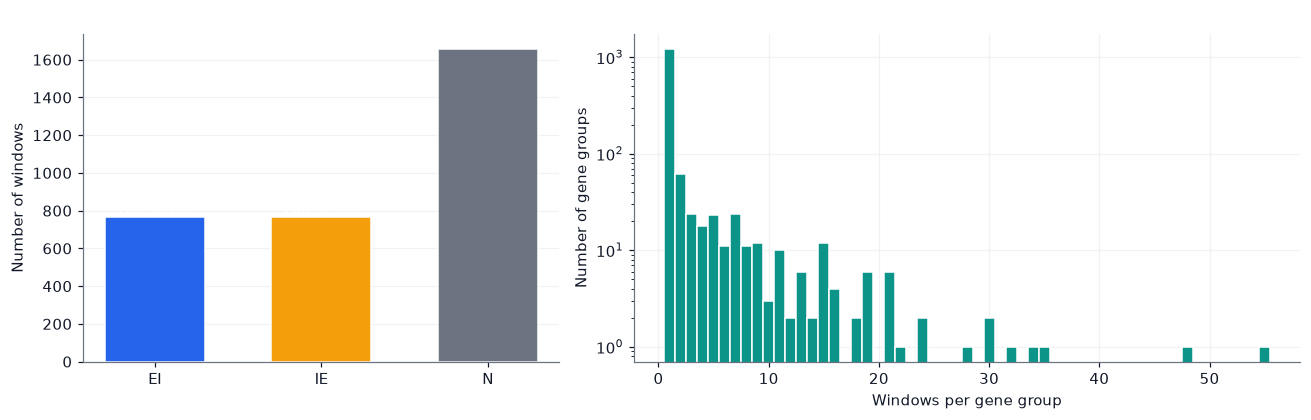

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1, 1.4]})
bars = axes[0].bar(CLASS_NAMES, counts.values, color=[CLASS_COLORS[c] for c in CLASS_NAMES], edgecolor="white", width=0.6)
for bar, c in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, c + 20, f"{c}  ({100 * c / len(splice):.0f}%)", ha="center", fontsize=9)
axes[0].set_ylabel("Number of windows"); axes[0].set_title("Class distribution"); axes[0].grid(axis="x", visible=False)
axes[1].hist(group_sizes.values, bins=np.arange(0.5, group_sizes.max() + 1.5, 1), color=COLORS["teal"], edgecolor="white")
axes[1].set_xlabel("Windows per gene group"); axes[1].set_ylabel("Number of gene groups"); axes[1].set_yscale("log")
axes[1].set_title("Many windows come from the same gene group")
finish(fig, "01_classes_and_groups")

## 5. Splitting: random or grouped by gene?

Because windows from the same gene (and from homologous genes) are related, a *random* split can place near-identical sequences in the training and test sets. A **grouped split** keeps all windows of one gene group in the same partition, so the test set contains only genes the model has never seen — a more honest estimate of how the model would handle new genes (Notebook 07, grouped splitting).

We build **both** splits (60% training, 20% validation, 20% test):

- the **grouped split** (greedy assignment of whole gene groups to the partition with the largest remaining deficit, largest groups first) is our **primary** split for model development and testing;
- the **random stratified split** is used only in Section 12 to measure how much optimism the random split adds.

Both are fixed by the random seed before any modelling.

In [8]:
def encode_labels(labels):
    return np.array([CLASS_NAMES.index(c) for c in labels], dtype="int32")

def stratified_split_indices(labels, val_fraction=0.2, test_fraction=0.2, seed=SEED):
    split_rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for c in np.unique(labels):
        idx = split_rng.permutation(np.flatnonzero(labels == c))
        n_val = max(1, int(round(val_fraction * len(idx)))); n_test = max(1, int(round(test_fraction * len(idx))))
        va.append(idx[:n_val]); te.append(idx[n_val:n_val + n_test]); tr.append(idx[n_val + n_test:])
    return [split_rng.permutation(np.concatenate(p)) for p in (tr, va, te)]

def grouped_split_indices(groups, fractions=(0.6, 0.2, 0.2), seed=SEED):
    """Assign WHOLE groups to partitions: groups in random order, then largest first, each to the partition with the largest deficit."""
    r = np.random.default_rng(seed)
    groups = np.asarray(groups)
    sizes = pd.Series(groups).value_counts()
    order = sorted(r.permutation(sizes.index.to_numpy()), key=lambda g: -sizes[g])        # stable sort: random among equal sizes
    targets = np.array(fractions) * len(groups); current = np.zeros(3)
    assigned = ([], [], [])
    for g in order:
        p = int(np.argmax(targets - current))
        assigned[p].append(g); current[p] += sizes[g]
    return [r.permutation(np.flatnonzero(np.isin(groups, assigned[p]))) for p in range(3)]

y_all = encode_labels(splice["label"])
splits = {"grouped": grouped_split_indices(splice["gene"].to_numpy()),
          "random": stratified_split_indices(y_all)}

for name, (tr, va, te) in splits.items():
    assert len(set(tr) | set(va) | set(te)) == len(y_all) and len(tr) + len(va) + len(te) == len(y_all)
    genes = [set(splice["gene"].iloc[i]) for i in (tr, va, te)]
    shared = len(genes[0] & genes[2])
    print(f"{name:8s} split | sizes {len(tr)} / {len(va)} / {len(te)} | class shares (EI, IE, N) of the test set: {np.round(np.bincount(y_all[te]) / len(te), 3)} | gene groups shared by training and test: {shared}")

grouped  split | sizes 1914 / 638 / 638 | class shares (EI, IE, N) of the test set: [0.114 0.114 0.771] | gene groups shared by training and test: 0
random   split | sizes 1914 / 638 / 638 | class shares (EI, IE, N) of the test set: [0.24  0.241 0.519] | gene groups shared by training and test: 161


## 6. Exploring the training sequences

All exploration and every statistic below use the **training** windows of the grouped split only.

### 6.1 One-hot encoding

A neural network needs numbers. Coding the nucleotides as integers ($A=0, C=1, G=2, T=3$) would impose an artificial **order and distance** (A and T would be "three apart", A and C "one apart"), which has no biological meaning. The **one-hot encoding** represents a nucleotide as a vector with a single 1:

$$
A = (1,0,0,0),\quad C = (0,1,0,0),\quad G = (0,0,1,0),\quad T = (0,0,0,1),
$$

so every pair of different nucleotides is at the same distance ($\sqrt{2}$). A sequence of length $L$ becomes a matrix $X \in \{0,1\}^{L \times 4}$, a 1D "image" with 4 channels. For the **ambiguity codes** we use *soft* one-hot vectors that spread the probability over the possible nucleotides: `N` (any) $= (\tfrac14,\tfrac14,\tfrac14,\tfrac14)$, `D` (A, G, or T) $= (\tfrac13, 0, \tfrac13, \tfrac13)$, `S` (C or G) $= (0, \tfrac12, \tfrac12, 0)$, `R` (A or G) $= (\tfrac12, 0, \tfrac12, 0)$.

### 6.2 An embedding is a one-hot layer

An `Embedding` layer maps each symbol to a learned vector (a row of a table $E \in \mathbb{R}^{4 \times d}$). This is *exactly* the product of the one-hot vector with $E$: $e(b) = \text{onehot}(b)^{\top}E$. A one-hot encoding followed by a Dense layer without bias is therefore an embedding; a convolution on one-hot DNA can learn whatever an embedding could.

In [9]:
SOFT_CODES = {"A": [1, 0, 0, 0], "C": [0, 1, 0, 0], "G": [0, 0, 1, 0], "T": [0, 0, 0, 1],
              "N": [0.25] * 4, "D": [1 / 3, 0, 1 / 3, 1 / 3], "S": [0, 0.5, 0.5, 0], "R": [0.5, 0, 0.5, 0]}

def one_hot_encode(sequences):
    X = np.zeros((len(sequences), len(sequences[0]), 4), dtype=np.float32)
    for i, seq in enumerate(sequences):
        for j, ch in enumerate(seq):
            X[i, j] = SOFT_CODES[ch]
    return X

X_all = one_hot_encode(splice["sequence"].tolist())
print("Encoded data:", X_all.shape, X_all.dtype, "| every position sums to 1:", np.allclose(X_all.sum(axis=2), 1.0))
print("First 6 positions of the first sequence:", splice["sequence"].iloc[0][:6])
print(X_all[0, :6])

# Distances between nucleotides: integer coding invents an order, one-hot does not.
ordinal = np.arange(4)
print("\nDistance between nucleotides  (rows/columns: A C G T)")
print("integer coding:\n", np.abs(ordinal[:, None] - ordinal[None, :]))
print("one-hot coding:\n", np.round(np.linalg.norm(np.eye(4)[:, None, :] - np.eye(4)[None, :, :], axis=2), 3))

# An Embedding layer equals one-hot times its table.
embedding = keras.layers.Embedding(4, 3)
ints = np.array([[0, 2, 1, 3, 3, 0]])
emb_out = keras.ops.convert_to_numpy(embedding(ints))
table = embedding.get_weights()[0]
print("\nEmbedding output equals onehot @ table:", np.allclose(emb_out, np.eye(4)[ints] @ table, atol=1e-6))

Encoded data: (3190, 60, 4) float32 | every position sums to 1: True
First 6 positions of the first sequence: CCAGCT
[[0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]]

Distance between nucleotides  (rows/columns: A C G T)
integer coding:
 [[0 1 2 3]
 [1 0 1 2]
 [2 1 0 1]
 [3 2 1 0]]
one-hot coding:
 [[0.    1.414 1.414 1.414]
 [1.414 0.    1.414 1.414]
 [1.414 1.414 0.    1.414]
 [1.414 1.414 1.414 0.   ]]

Embedding output equals onehot @ table: True


### 6.3 Position-specific nucleotide frequencies and sequence logos

For each class $c$ and position $i$, the **position frequency matrix (PFM)** holds the fraction $p_c(i, b)$ of training windows with nucleotide $b$ at position $i$. The **information content** of a position, in bits, measures how far its distribution is from uniform:

$$
IC(i) = 2 + \sum_{b \in \{A,C,G,T\}} p(i, b)\log_2 p(i, b) \in [0, 2],
$$

($2$ bits for a position that is always the same base, $0$ for a uniform one). A **sequence logo** stacks the letters at each position with height $p(i,b)\cdot IC(i)$. (Logos for very small samples additionally apply a small-sample correction; with hundreds of windows per class we omit it.)

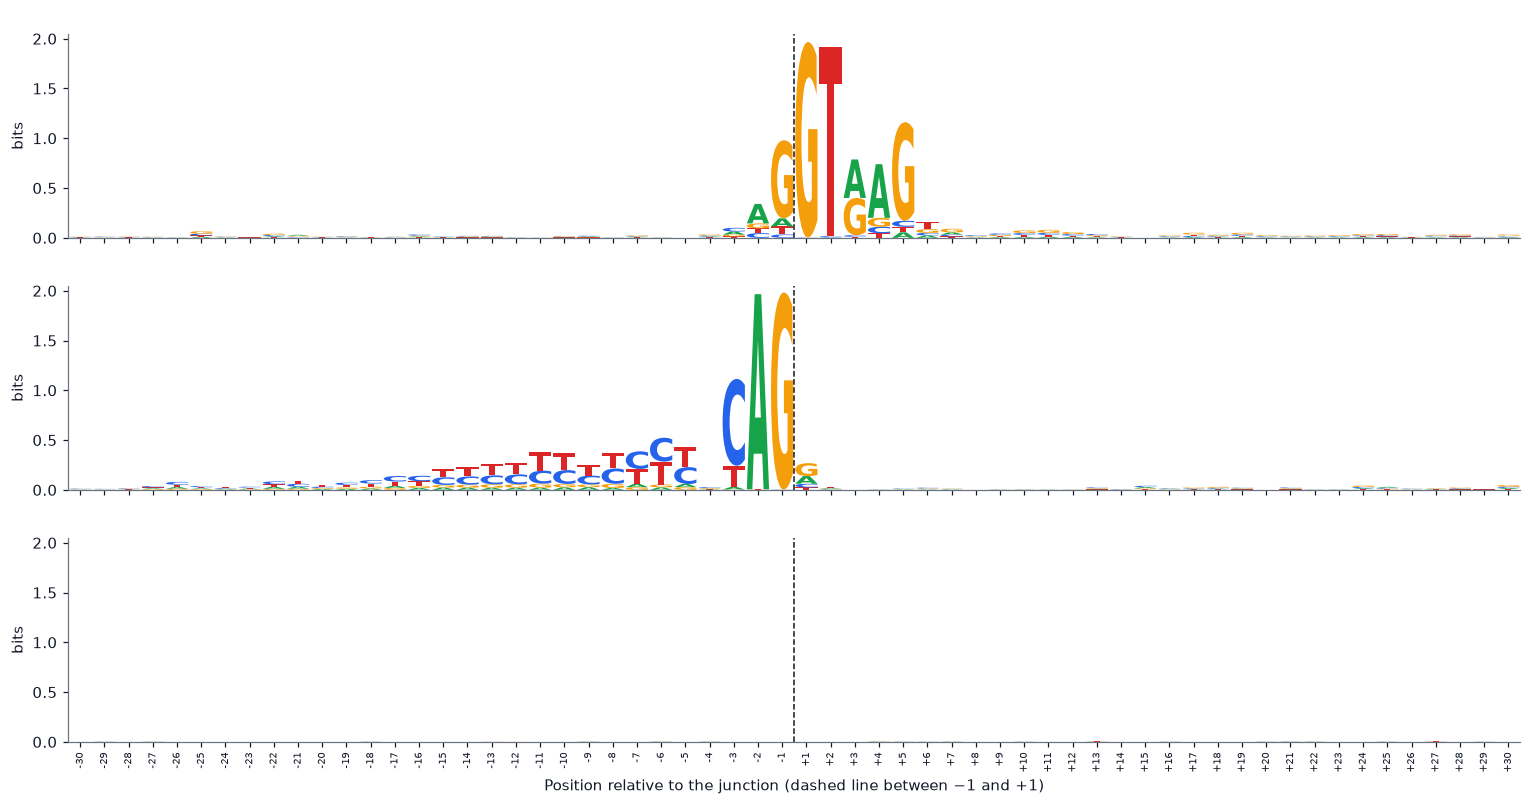

In [10]:
tr_g, va_g, te_g = splits["grouped"]
X_tr, y_tr, X_va, y_va, X_te, y_te = X_all[tr_g], y_all[tr_g], X_all[va_g], y_all[va_g], X_all[te_g], y_all[te_g]
seq_tr, seq_te = splice["sequence"].iloc[tr_g].to_numpy(), splice["sequence"].iloc[te_g].to_numpy()
names_te = splice["name"].iloc[te_g].to_numpy()
L = X_all.shape[1]
pos_labels = [str(i) for i in range(-30, 0)] + [f"+{i}" for i in range(1, 31)]            # the junction lies between -1 and +1

pfm = {c: X_tr[y_tr == i].mean(axis=0) for i, c in enumerate(CLASS_NAMES)}              # (60, 4) per class
information = lambda p: 2 + np.sum(np.where(p > 0, p * np.log2(np.where(p > 0, p, 1)), 0), axis=1)

def draw_logo(ax, p, title):
    heights = p * information(p)[:, None]
    font = FontProperties(family="DejaVu Sans", weight="bold")
    for i in range(p.shape[0]):
        y0 = 0.0
        for b in np.argsort(heights[i]):
            h = heights[i, b]
            if h < 1e-3:
                continue
            path = TextPath((0, 0), BASES[b], size=1, prop=font)
            bb = path.get_extents()
            transform = Affine2D().translate(-bb.x0, -bb.y0).scale(0.92 / bb.width, h / bb.height).translate(i + 0.04, y0)
            ax.add_patch(PathPatch(transform.transform_path(path), facecolor=BASE_COLORS[BASES[b]], edgecolor="none"))
            y0 += h
    ax.set_xlim(0, p.shape[0]); ax.set_ylim(0, 2.05)
    ax.axvline(30, color=COLORS["dark"], linestyle="--", linewidth=1)
    ax.set_xticks(np.arange(p.shape[0]) + 0.5); ax.set_xticklabels(pos_labels, rotation=90, fontsize=6.5)
    ax.set_ylabel("bits"); ax.set_title(title); ax.grid(False)

fig, axes = plt.subplots(3, 1, figsize=(14, 7.4), sharex=True)
for ax, c in zip(axes, CLASS_NAMES):
    draw_logo(ax, pfm[c], f"Class {c}  ({int(np.sum(y_tr == CLASS_NAMES.index(c)))} training windows)")
axes[-1].set_xlabel("Position relative to the junction (dashed line between \u22121 and +1)")
finish(fig, "02_sequence_logos")

C:\Users\mobin\AppData\Local\Temp\ipykernel_10268\1802210887.py:23: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=pad)


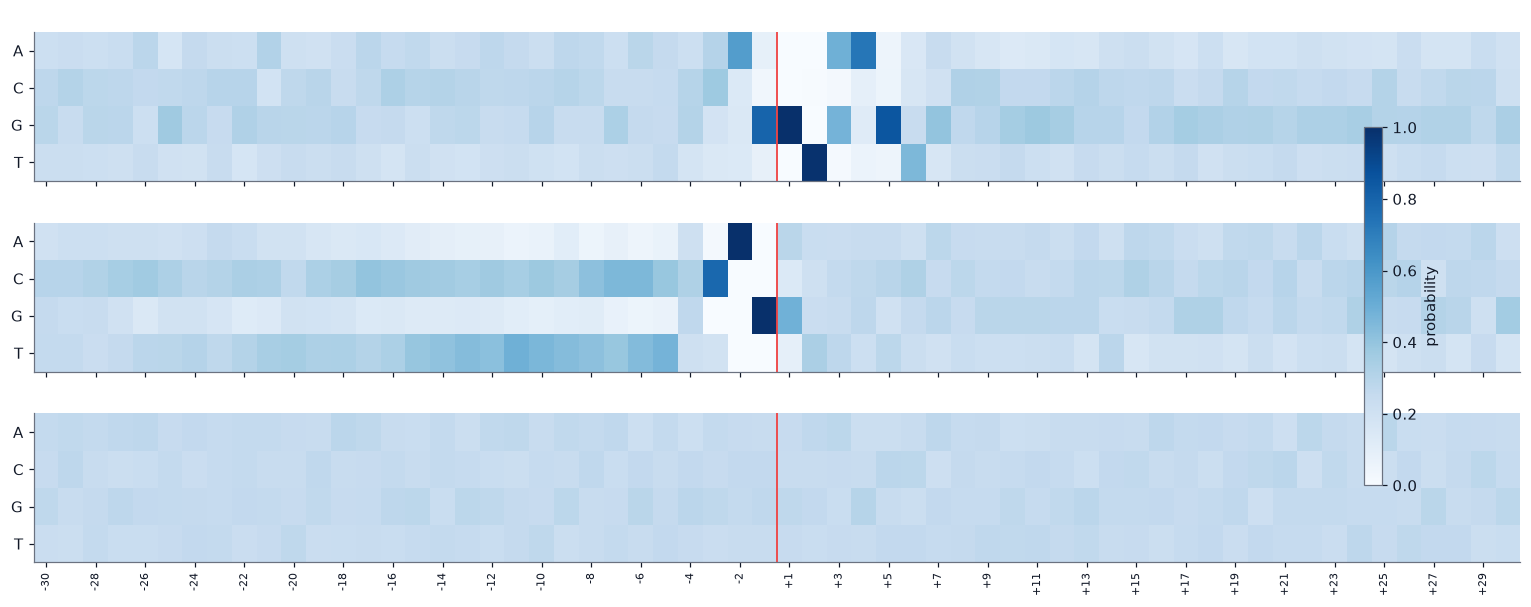

,windows,"GT at +1,+2","AG at −2,−1"
class,,,
EI,614,0.990,0.493
IE,615,0.150,0.995
N,685,0.039,0.077


GT occurs at ANY of the 59 dinucleotide positions of a window in 0.936 of the 'N' windows: the dinucleotide alone is a weak signal.


In [11]:
fig, axes = plt.subplots(3, 1, figsize=(14, 5.6), sharex=True)
for ax, c in zip(axes, CLASS_NAMES):
    im = ax.imshow(pfm[c].T, aspect="auto", cmap="Blues", vmin=0, vmax=1)
    ax.set_yticks(range(4)); ax.set_yticklabels(list(BASES)); ax.grid(False); ax.axvline(29.5, color=COLORS["red"], linewidth=1.2)
    ax.set_title(f"Class {c}: probability of each nucleotide at each position", fontsize=10.5)
axes[-1].set_xticks(range(0, L, 2)); axes[-1].set_xticklabels(pos_labels[::2], rotation=90, fontsize=7)
fig.colorbar(im, ax=axes, fraction=0.015, pad=0.01, label="probability")
finish(fig, "03_position_frequencies")

# The canonical dinucleotides: GT at +1,+2 (donor, EI) and AG at -2,-1 (acceptor, IE).
rows = []
for i, c in enumerate(CLASS_NAMES):
    s = seq_tr[y_tr == i]
    rows.append({"class": c, "windows": len(s), "GT at +1,+2": np.mean([q[30:32] == "GT" for q in s]), "AG at \u22122,\u22121": np.mean([q[28:30] == "AG" for q in s])})
canonical = pd.DataFrame(rows).set_index("class")
display(canonical.round(3))
print("GT occurs at ANY of the 59 dinucleotide positions of a window in", round(float(np.mean([q.count("GT") >= 1 for q in seq_tr[y_tr == 2]])), 3),
      "of the 'N' windows: the dinucleotide alone is a weak signal.")

What the figures show (compare with your own plots):

- **Donor (`EI`)**: strong, almost deterministic information at positions $+1$ and $+2$ (GT), and extra information at $-3, -2, -1$ (the end of the exon) and at $+3 \dots +6$ (the intron start).
- **Acceptor (`IE`)**: AG at $-2$ and $-1$, and a **pyrimidine-rich stretch** (C and T) upstream, from about $-15$ to $-3$ (the polypyrimidine tract).
- **`N` windows**: close to uniform at every position (low information everywhere).
- The table confirms the canonical dinucleotides, and shows that GT or AG also occur in many `N` windows, which is why a model must use the *context*.

## 7. A classical baseline: the position weight matrix (PWM)

Biologists have long used **position weight matrices** to recognize motifs. Treat the nucleotides at different positions as independent *given the class*: the likelihood of a window $x$ under class $c$ is

$$
P(x \mid c) = \prod_{i=1}^{L} p_c(i, x_i), \qquad
\log P(x \mid c) = \sum_{i=1}^{L}\sum_{b} X_{i,b}\,\log p_c(i, b),
$$

and by Bayes' theorem the class posterior is $P(c \mid x) \propto P(c)\,P(x \mid c)$. This is a **position-specific naive Bayes classifier**. We estimate $p_c(i, b)$ from the training windows with a **pseudocount** $\alpha$ (here 0.5) to avoid taking the logarithm of zero: $p_c(i,b) = (n_c(i,b) + \alpha)/(n_c + 4\alpha)$. The matrix of $\log p_c(i, b)$, or of the **log-odds** $\log\big(p_c(i,b)/p_{\text{bg}}(b)\big)$ against a background distribution, is the PWM.

The PWM classifier is a *linear* model in the one-hot features (a linear function of $X$ in the log-domain) that ignores any **interaction between positions** and any **motif shifting**. It is our baseline, and the reference that a neural network must beat.

In [12]:
def fit_pwm(X, labels, pseudocount=0.5, n_classes=3):
    logp = []
    for c in range(n_classes):
        counts = X[labels == c].sum(axis=0) + pseudocount                             # (L, 4)
        logp.append(np.log(counts / counts.sum(axis=1, keepdims=True)))
    prior = np.bincount(labels, minlength=n_classes) / len(labels)
    return np.stack(logp), np.log(prior)

def pwm_log_posterior(X, logp, log_prior):
    return np.einsum("npb,cpb->nc", X, logp) + log_prior                              # log P(x | c) + log P(c)

def softmax_np(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

pwm_logp, pwm_log_prior = fit_pwm(X_tr, y_tr)
pwm_val_probs = softmax_np(pwm_log_posterior(X_va, pwm_logp, pwm_log_prior))
print("PWM baseline, validation accuracy:", round(float(np.mean(pwm_val_probs.argmax(1) == y_va)), 4))
print("Majority-class accuracy (always 'N'):", round(float(np.mean(y_va == 2)), 4))

PWM baseline, validation accuracy: 0.9404
Majority-class accuracy (always 'N'): 0.7492


## 8. The one-dimensional convolution

### 8.1 Definition

For a one-hot sequence $X \in \mathbb{R}^{L \times C_{in}}$ ($C_{in} = 4$), a bank of $F$ filters $K \in \mathbb{R}^{k \times C_{in} \times F}$, biases $b$, stride $s$, and zero padding:

$$
Y_{i,f} = b_f + \sum_{m=0}^{k-1}\sum_{c=1}^{C_{in}} \tilde{X}_{\,s i + m,\; c}\;K_{m,c,f},
\qquad
L_{out} = \Big\lfloor \frac{L + 2p - k}{s} \Big\rfloor + 1 .
$$

It is the 2D convolution of Notebook 08 with one spatial axis. As there, `"valid"` means no padding and `"same"` gives $L_{out} = \lceil L/s \rceil$ (with the extra zero, if the total padding is odd, placed after the sequence). The number of parameters is $(k\,C_{in} + 1)F$ and the number of multiply–accumulate operations is $L_{out}\,k\,C_{in}\,F$.

### 8.2 A filter on one-hot DNA is a motif detector

Because $X_{i+m,\,c}$ is 1 for the observed nucleotide and 0 otherwise, the sum over $c$ **selects one entry of each row of the kernel**:

$$
Y_{i,f} = b_f + \sum_{m=0}^{k-1} K_{m,\;x_{i+m},\;f} .
$$

So the response of a filter at position $i$ is the sum of the weights $K_{m,b}$ of the nucleotides actually found in the $k$-mer starting at $i$. If $K$ is a PWM (a matrix of log-odds), the response is **exactly the PWM log-odds score of that $k$-mer**. Scanning a PWM along a sequence *is* a 1D convolution, and a network that learns its filters learns its own PWMs. We verify this exactly and then use it on real data.

In [13]:
def pad_amounts(n, k, s, padding):
    if padding == "valid":
        return 0, 0
    out = -(-n // s)
    total = max((out - 1) * s + k - n, 0)
    return total // 2, total - total // 2

def conv1d_numpy(x, kernel, bias, stride=1, padding="valid"):
    """x (N, L, Cin), kernel (k, Cin, F), bias (F,) -> (N, L_out, F)."""
    N, Ln, _ = x.shape
    k, _, F = kernel.shape
    pb, pa = pad_amounts(Ln, k, stride, padding)
    xp = np.pad(x, ((0, 0), (pb, pa), (0, 0)))
    Lo = (xp.shape[1] - k) // stride + 1
    out = np.zeros((N, Lo, F))
    for m in range(k):
        out += xp[:, m:m + stride * Lo:stride, :] @ kernel[m]
    return out + bias

# (1) Scanning a PWM = convolution. A random "log-odds" matrix of width 6, five random sequences.
rg = np.random.default_rng(0)
k_pwm = 6
pwm_matrix = rg.normal(size=(k_pwm, 4))
seqs = rg.integers(0, 4, size=(5, 40))                                           # integer-coded sequences
onehot = np.eye(4)[seqs]                                                          # (5, 40, 4)
scan = np.array([[sum(pwm_matrix[m, seqs[n, i + m]] for m in range(k_pwm)) for i in range(40 - k_pwm + 1)] for n in range(5)])
conv = conv1d_numpy(onehot, pwm_matrix[:, :, None], np.zeros(1))[:, :, 0]
print("PWM scan (explicit loop over positions) equals conv1d with the PWM as kernel; max difference:", float(np.abs(scan - conv).max()))
assert np.allclose(scan, conv)

# (2) Our implementation against Keras, including the asymmetric 'same' padding of an even kernel.
def check_conv1d_keras(n, k, s, padding, c_in=4, f=3, seed=0):
    r = np.random.default_rng(seed)
    x = r.normal(size=(2, n, c_in)).astype("float32")
    layer = keras.layers.Conv1D(f, k, strides=s, padding=padding)
    layer(x)
    K_, b_ = r.normal(size=(k, c_in, f)).astype("float32"), r.normal(size=(f,)).astype("float32")
    layer.set_weights([K_, b_])
    out_k = keras.ops.convert_to_numpy(layer(x))
    out_n = conv1d_numpy(x.astype(float), K_.astype(float), b_.astype(float), s, padding)
    expected_len = (n - k) // s + 1 if padding == "valid" else -(-n // s)
    return out_k.shape[1], expected_len, float(np.abs(out_k - out_n).max())

print(f"\n{'L':>3} {'k':>2} {'s':>2} {'padding':>8} | {'Keras length':>12} | {'formula':>7} | {'max |difference|':>16}")
for n, k, s, padding in [(60, 5, 1, "valid"), (60, 5, 1, "same"), (60, 6, 1, "same"), (60, 7, 2, "valid"), (59, 4, 2, "same")]:
    got, expected_len, diff = check_conv1d_keras(n, k, s, padding)
    print(f"{n:>3} {k:>2} {s:>2} {padding:>8} | {got:>12} | {expected_len:>7} | {diff:>16.2e}")
    assert got == expected_len and diff < 1e-4
print("Lengths and values agree with Keras.")

PWM scan (explicit loop over positions) equals conv1d with the PWM as kernel; max difference: 0.0

  L  k  s  padding | Keras length | formula | max |difference|
 60  5  1    valid |           56 |      56 |         1.19e-06
 60  5  1     same |           60 |      60 |         1.43e-06
 60  6  1     same |           60 |      60 |         1.50e-06
 60  7  2    valid |           27 |      27 |         2.10e-06
 59  4  2     same |           30 |      30 |         1.21e-06
Lengths and values agree with Keras.


### 8.3 The backward pass of a 1D convolution

As in Notebook 08, with upstream gradient $dY = \partial L/\partial Y$ (valid padding, stride 1):

$$
\frac{\partial L}{\partial K_{m,c,f}} = \sum_{i} X_{i+m,\,c}\;dY_{i,f}, \qquad
\frac{\partial L}{\partial b_f} = \sum_{i} dY_{i,f}, \qquad
\frac{\partial L}{\partial X_{p,c}} = \sum_{f}\sum_{m} dY_{p-m,\,f}\;K_{m,c,f} .
$$

The kernel gradient is a correlation of the input with the upstream gradient (summing over all positions, because the kernel is shared); for one-hot input it simply **adds the upstream gradient to the kernel row of the nucleotide that was present**. We verify it numerically with the loss $L = \sum_{i,f} R_{i,f}\operatorname{ReLU}(Z_{i,f})$.

In [14]:
def conv1d_forward(X, K, b):                      # X (L, Cin), K (k, Cin, F) -> (L_out, F)
    return conv1d_numpy(X[None], K, b)[0]

def conv1d_backward(X, K, dZ):
    k, Cin, F = K.shape
    Lo = dZ.shape[0]
    dK = np.zeros_like(K); dX = np.zeros_like(X)
    for m in range(k):
        for c in range(Cin):
            for f in range(F):
                dK[m, c, f] = np.sum(X[m:m + Lo, c] * dZ[:, f])
    for i in range(Lo):
        for f in range(F):
            dX[i:i + k, :] += dZ[i, f] * K[:, :, f]
    return dX, dK, dZ.sum(axis=0)

rg = np.random.default_rng(1)
X_g, K_g, b_g = rg.normal(size=(12, 4)), rg.normal(size=(4, 4, 3)), rg.normal(size=3)
R_g = rg.normal(size=(9, 3))
loss_fn = lambda X, K, b: float(np.sum(R_g * np.maximum(conv1d_forward(X, K, b), 0)))
Z_g = conv1d_forward(X_g, K_g, b_g)
analytic = conv1d_backward(X_g, K_g, R_g * (Z_g > 0))

def numeric_grad(index, eps=1e-6):
    params = [X_g.copy(), K_g.copy(), b_g.copy()]
    g = np.zeros_like(params[index])
    for idx in np.ndindex(*params[index].shape):
        o = params[index][idx]
        params[index][idx] = o + eps; plus = loss_fn(*params)
        params[index][idx] = o - eps; minus = loss_fn(*params)
        params[index][idx] = o; g[idx] = (plus - minus) / (2 * eps)
    return g

print(f"{'gradient':>8} | relative error")
for name, a, index in [("dL/dX", analytic[0], 0), ("dL/dK", analytic[1], 1), ("dL/db", analytic[2], 2)]:
    num = numeric_grad(index)
    rel = np.linalg.norm(a - num) / (np.linalg.norm(a) + np.linalg.norm(num))
    print(f"{name:>8} | {rel:.2e}")
    assert rel < 1e-6
print("The analytic gradients of the 1D convolution match the numerical gradients.")

gradient | relative error
   dL/dX | 3.08e-10
   dL/dK | 3.16e-10
   dL/db | 1.99e-10
The analytic gradients of the 1D convolution match the numerical gradients.


### 8.4 Pooling over positions: motif *presence* or motif *position*?

After a convolution, each filter has one response per position. Two common ways to summarize them:

| Operation | Output | What it keeps | Typical use |
|---|---|---|---|
| **Global max pooling** | one number per filter: $\max_i Y_{i,f}$ | *whether* the motif occurs anywhere, ignoring *where* | motif presence in sequences of varying length (transcription-factor binding, promoters) |
| **Flatten** (after optional local pooling) | all positions kept | *where* the motif occurs | problems where position matters |

For splice junctions the **position matters**: the junction is always at the centre, and a GT at position $+1,+2$ means a donor, while the same GT 10 positions away means nothing. Global max pooling discards this information, so we expect a position-aware design to be better. We can check this directly with the filter of Section 8.2: a PWM for the donor, built from the log-odds of `EI` against `N` windows at the *central* positions $+1\ldots$, applied as a convolution to the validation windows. We compare its score at the position where it was built ("home position") with its maximum over all positions.

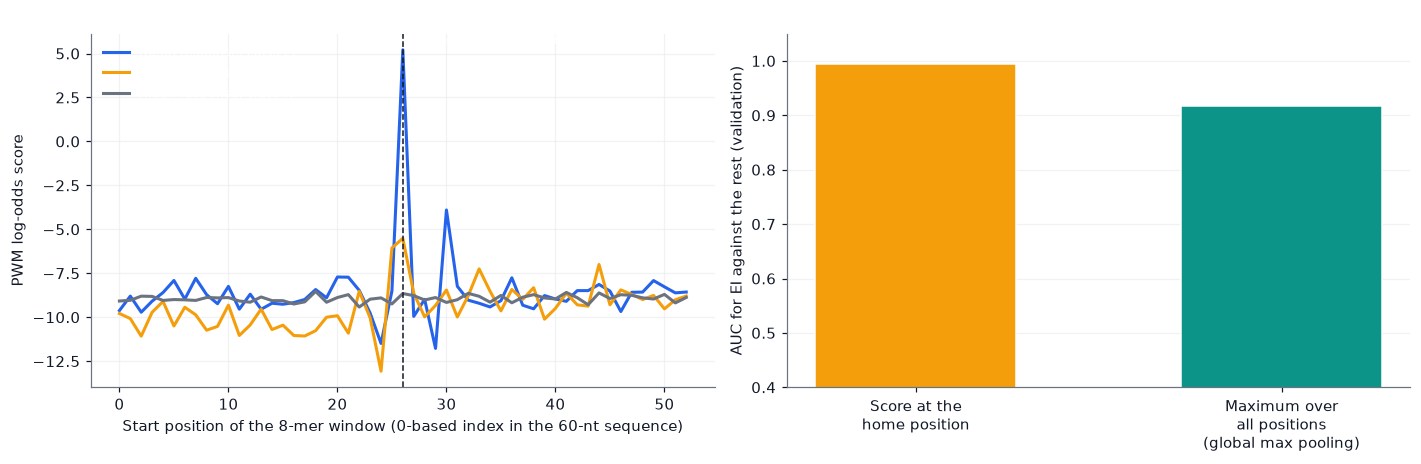

AUC of the donor PWM for EI against the rest: home position 0.994 | maximum over positions 0.917


In [15]:
def auc_rank(y_true, score):
    """AUC = P(score of a positive > score of a negative), via average ranks (Mann-Whitney)."""
    y_true = np.asarray(y_true).astype(bool)
    n_pos, n_neg = y_true.sum(), (~y_true).sum()
    order = np.argsort(score, kind="stable"); ranks = np.empty(len(score)); sorted_s = np.asarray(score)[order]
    i = 0
    while i < len(score):
        j = i
        while j + 1 < len(score) and sorted_s[j + 1] == sorted_s[i]:
            j += 1
        ranks[order[i:j + 1]] = (i + j) / 2 + 1; i = j + 1
    return float((ranks[y_true].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))

home, width = 26, 8                                                                # positions 26..33 (0-based): -4 ... +4
donor_pwm = (pwm_logp[0] - pwm_logp[2])[home:home + width]                         # log-odds EI against N for these positions
response = conv1d_numpy(X_va, donor_pwm[:, :, None], np.zeros(1))[:, :, 0]         # (N, L - width + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
x_axis = np.arange(response.shape[1])
for i, c in enumerate(CLASS_NAMES):
    axes[0].plot(x_axis, response[y_va == i].mean(axis=0), color=CLASS_COLORS[c], label=f"mean response, class {c}")
axes[0].axvline(home, color=COLORS["dark"], linestyle="--", linewidth=1); axes[0].annotate("home position of the donor PWM", (home, axes[0].get_ylim()[1] * 0.9), fontsize=8.5, xytext=(5, 0), textcoords="offset points")
axes[0].set_xlabel("Start position of the 8-mer window (0-based index in the 60-nt sequence)"); axes[0].set_ylabel("PWM log-odds score")
axes[0].set_title("Scanning a donor PWM along the windows (a 1D convolution)"); axes[0].legend(fontsize=8.5)

is_ei = (y_va == 0).astype(int)
auc_home, auc_max = auc_rank(is_ei, response[:, home]), auc_rank(is_ei, response.max(axis=1))
bars = axes[1].bar(["Score at the\nhome position", "Maximum over\nall positions\n(global max pooling)"], [auc_home, auc_max], color=[COLORS["orange"], COLORS["teal"]], width=0.55, edgecolor="white")
for b_, v in zip(bars, [auc_home, auc_max]):
    axes[1].text(b_.get_x() + b_.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=10)
axes[1].set_ylim(0.4, 1.05); axes[1].set_ylabel("AUC for EI against the rest (validation)")
axes[1].set_title("Position matters: discarding it costs discrimination"); axes[1].grid(axis="x", visible=False)
finish(fig, "04_pwm_scan_and_position")
print(f"AUC of the donor PWM for EI against the rest: home position {auc_home:.3f} | maximum over positions {auc_max:.3f}")

# Part II — Models and experiments

## 9. Three architectures

All three take the one-hot window $(60 \times 4)$ and output three class probabilities.

| Model | Architecture | Idea |
|---|---|---|
| **MLP on one-hot** | `Flatten` → `Dense(64, ReLU)` → `Dropout(0.3)` → `Dense(3, softmax)` | no weight sharing: every position has its own weights; uses position |
| **CNN + global max pooling** | `Conv1D(32, 7)` → `Conv1D(64, 5)` → `GlobalMaxPooling1D` → `Dropout` → `Dense(3)` | position-independent *motif presence* detector |
| **CNN + Flatten (position-aware)** | `Conv1D(32, 7)` → `MaxPooling1D(2)` → `Conv1D(64, 5)` → `MaxPooling1D(2)` → `Flatten` → `Dropout` → `Dense(3)` | local motif detectors, **followed by position-specific weights** |

Convolutions use `"same"` padding so that the positions stay aligned with the original window. The PWM of Section 7 is the **classical baseline**. Based on Section 8.4 we expect the position-aware models to do better than global max pooling; we will see.

In [16]:
def build_mlp(name="mlp_onehot"):
    return keras.Sequential([keras.layers.Input(shape=(L, 4), name="sequence"), keras.layers.Flatten(name="flatten"),
                             keras.layers.Dense(64, activation="relu", name="dense"), keras.layers.Dropout(0.3, name="dropout"),
                             keras.layers.Dense(3, activation="softmax", name="class_probabilities")], name=name)

def build_cnn_global_max(name="cnn_global_max"):
    return keras.Sequential([keras.layers.Input(shape=(L, 4), name="sequence"),
                             keras.layers.Conv1D(32, 7, padding="same", activation="relu", name="conv_1"),
                             keras.layers.Conv1D(64, 5, padding="same", activation="relu", name="conv_2"),
                             keras.layers.GlobalMaxPooling1D(name="global_max"), keras.layers.Dropout(0.3, name="dropout"),
                             keras.layers.Dense(3, activation="softmax", name="class_probabilities")], name=name)

def build_cnn_flatten(name="cnn_flatten"):
    return keras.Sequential([keras.layers.Input(shape=(L, 4), name="sequence"),
                             keras.layers.Conv1D(32, 7, padding="same", activation="relu", name="conv_1"), keras.layers.MaxPooling1D(2, name="pool_1"),
                             keras.layers.Conv1D(64, 5, padding="same", activation="relu", name="conv_2"), keras.layers.MaxPooling1D(2, name="pool_2"),
                             keras.layers.Flatten(name="flatten"), keras.layers.Dropout(0.3, name="dropout"),
                             keras.layers.Dense(3, activation="softmax", name="class_probabilities")], name=name)

builders = {"MLP on one-hot": build_mlp, "CNN + global max pooling": build_cnn_global_max, "CNN + Flatten (position-aware)": build_cnn_flatten}
for name, builder in builders.items():
    print(f"{name:34s} {builder().count_params():>8,} parameters")
print("Check of the formula (k * C_in + 1) * F for the first convolution: (7 * 4 + 1) * 32 =", (7 * 4 + 1) * 32)

MLP on one-hot                       15,619 parameters
CNN + global max pooling             11,427 parameters
CNN + Flatten (position-aware)       14,115 parameters
Check of the formula (k * C_in + 1) * F for the first convolution: (7 * 4 + 1) * 32 = 928


## 10. Training with several seeds and comparing on the validation set

Every architecture is trained with `N_SEEDS` different random seeds (initialization and mini-batch order), with Adam ($10^{-3}$), batch size 64, and early stopping on the validation loss (patience 10, best weights restored). We report **mean ± standard deviation over seeds**; as in Notebook 06, a single run cannot separate an architectural effect from random variation.

Metrics: accuracy, **macro-F1** (the three classes are imbalanced: 50% `N`), and the Matthews correlation coefficient (Notebook 04). Declared selection rule: **the architecture with the highest mean validation macro-F1** (the PWM is the baseline and is not part of the selection).

In [17]:
def confusion_matrix_np(y_true, y_pred, n_classes=3):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

def summary_metrics(cm):
    cm = np.asarray(cm, dtype=float)
    tp, predicted, support = np.diag(cm), cm.sum(axis=0), cm.sum(axis=1)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    total = cm.sum()
    d = np.sqrt((total**2 - np.sum(predicted**2)) * (total**2 - np.sum(support**2)))
    return {"accuracy": float(np.trace(cm) / total), "macro_f1": float(f1[support > 0].mean()),
            "mcc": float((np.trace(cm) * total - np.sum(predicted * support)) / d) if d > 0 else 0.0}

def metrics_from_probs(probs, labels):
    return summary_metrics(confusion_matrix_np(labels, probs.argmax(axis=1)))

def train_seq_model(builder, arrays, seed, epochs=100, patience=10):
    keras.utils.set_random_seed(seed)
    model = builder()
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")])
    history = model.fit(arrays["X_tr"], arrays["y_tr"], validation_data=(arrays["X_va"], arrays["y_va"]), epochs=epochs, batch_size=64,
                        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)], verbose=0)
    return model, history.history

grouped_arrays = {"X_tr": X_tr, "y_tr": y_tr, "X_va": X_va, "y_va": y_va, "X_te": X_te, "y_te": y_te}
seeds = list(range(SEED, SEED + N_SEEDS))

trained, histories = {}, {}
t0 = time.time()
for name, builder in builders.items():
    runs = [train_seq_model(builder, grouped_arrays, s) for s in seeds]
    trained[name] = [m for m, _ in runs]; histories[name] = [h for _, h in runs]
    print(f"{name:34s} epochs run per seed: {[len(h['loss']) for _, h in runs]}")
print(f"Done in {time.time() - t0:.0f} s")

MLP on one-hot                     epochs run per seed: [21, 23, 26, 22, 21]
CNN + global max pooling           epochs run per seed: [32, 28, 47, 40, 40]
CNN + Flatten (position-aware)     epochs run per seed: [27, 21, 59, 34, 33]
Done in 100 s


,parameters,val accuracy,val macro-F1,val MCC
model,,,,
PWM baseline,720,0.940,0.909,0.868
MLP on one-hot,15619,0.947 ± 0.004,0.918 ± 0.006,0.879 ± 0.009
CNN + global max pooling,11427,0.769 ± 0.021,0.699 ± 0.019,0.559 ± 0.020
CNN + Flatten (position-aware),14115,0.959 ± 0.009,0.936 ± 0.013,0.904 ± 0.020


Selected architecture (highest mean validation macro-F1): CNN + Flatten (position-aware)


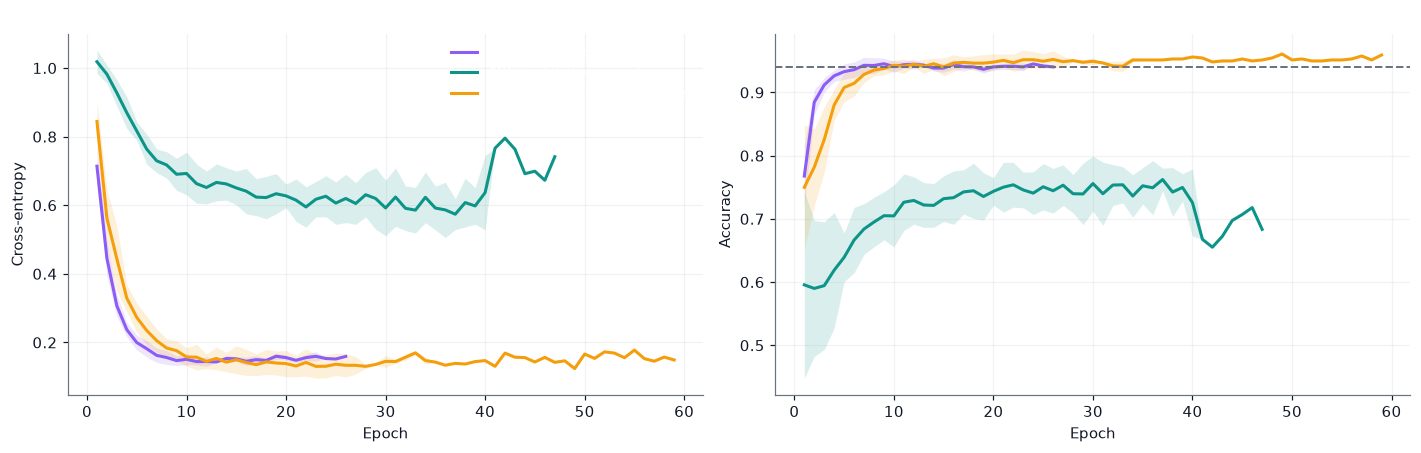

In [18]:
def val_metrics_of(models):
    return [metrics_from_probs(m.predict(X_va, verbose=0), y_va) for m in models]

rows = []
pwm_val = metrics_from_probs(pwm_val_probs, y_va)
rows.append({"model": "PWM baseline", "parameters": int(np.prod(pwm_logp.shape)), "val accuracy": f"{pwm_val['accuracy']:.3f}", "val macro-F1": f"{pwm_val['macro_f1']:.3f}", "val MCC": f"{pwm_val['mcc']:.3f}"})
val_mean_f1 = {}
for name in builders:
    vm = val_metrics_of(trained[name])
    val_mean_f1[name] = float(np.mean([m["macro_f1"] for m in vm]))
    rows.append({"model": name, "parameters": trained[name][0].count_params(),
                 "val accuracy": f"{np.mean([m['accuracy'] for m in vm]):.3f} \u00b1 {np.std([m['accuracy'] for m in vm]):.3f}",
                 "val macro-F1": f"{val_mean_f1[name]:.3f} \u00b1 {np.std([m['macro_f1'] for m in vm]):.3f}",
                 "val MCC": f"{np.mean([m['mcc'] for m in vm]):.3f} \u00b1 {np.std([m['mcc'] for m in vm]):.3f}"})
display(pd.DataFrame(rows).set_index("model"))
selected = max(val_mean_f1, key=val_mean_f1.get)
print("Selected architecture (highest mean validation macro-F1):", selected)

def padded(curves):
    n = max(len(c) for c in curves)
    return np.array([list(c) + [np.nan] * (n - len(c)) for c in curves])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name in builders:
    for ax, key in zip(axes, ["val_loss", "val_accuracy"]):
        arr = padded([h[key] for h in histories[name]])
        mean, sd = np.nanmean(arr, axis=0), np.nanstd(arr, axis=0)
        x = np.arange(1, len(mean) + 1)
        ax.plot(x, mean, color=MODEL_COLORS[name], label=name); ax.fill_between(x, mean - sd, mean + sd, color=MODEL_COLORS[name], alpha=0.15, linewidth=0)
axes[0].set_title("Validation loss (mean \u00b1 SD over seeds)"); axes[0].set_ylabel("Cross-entropy")
axes[1].set_title("Validation accuracy"); axes[1].set_ylabel("Accuracy"); axes[1].axhline(pwm_val["accuracy"], color=MODEL_COLORS["PWM baseline"], linestyle="--", linewidth=1.3, label="PWM baseline")
for ax in axes:
    ax.set_xlabel("Epoch")
axes[0].legend(fontsize=8.5)
finish(fig, "05_training_curves")

Compare the three architectures and the baseline (your numbers may differ from what is described here): the PWM baseline is already strong, because the problem has clear position-specific signals; the models that **use position** (the MLP and the position-aware CNN) are expected to do at least as well as the PWM, while global max pooling, which throws away *where* a motif occurs, tends to be the weakest. The standard deviations over seeds show how much of any difference between architectures could be due to chance.

## 11. Final evaluation on the test set

We evaluate the **selected architecture** as an **ensemble** of its `N_SEEDS` trained networks: the predicted probabilities are averaged,

$$
\hat{p}_{\text{ens}}(x) = \frac{1}{S}\sum_{s=1}^{S}\hat{p}_s(x).
$$

Averaging reduces the variance caused by random initialization (the same variance-reduction idea as test-time augmentation in Notebook 09). The test set is used **once**, with the metrics and intervals of Notebook 07:

- accuracy, macro-F1, and MCC with **bootstrap** 95% intervals;
- per-class precision, recall (with **Wilson** intervals), and F1;
- **one-vs-rest ROC curves and AUC**;
- a **paired comparison with the PWM baseline** on the same test windows (McNemar's exact test and a paired bootstrap interval).

In [19]:
def wilson_interval(k, n, z=1.959964):
    if n == 0:
        return 0.0, 1.0
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)

def mcnemar_exact(correct_a, correct_b):
    correct_a, correct_b = np.asarray(correct_a, dtype=bool), np.asarray(correct_b, dtype=bool)
    b, c = int(np.sum(correct_a & ~correct_b)), int(np.sum(~correct_a & correct_b))
    n = b + c
    if n == 0:
        return b, c, 1.0
    return b, c, min(1.0, 2 * sum(comb(n, i) for i in range(min(b, c) + 1)) / 2**n)

def ensemble_predict(models, X):
    return np.mean([m.predict(X, verbose=0) for m in models], axis=0)

ens_models = trained[selected]
test_probs = ensemble_predict(ens_models, X_te)
pwm_test_probs = softmax_np(pwm_log_posterior(X_te, pwm_logp, pwm_log_prior))
pred_te, pwm_pred_te = test_probs.argmax(1), pwm_test_probs.argmax(1)

def bootstrap_metrics(y_true, pred, n_boot=N_BOOT, seed=0):
    r = np.random.default_rng(seed); n = len(y_true); out = {"accuracy": [], "macro_f1": [], "mcc": []}
    for _ in range(n_boot):
        idx = r.integers(0, n, size=n)
        m = summary_metrics(confusion_matrix_np(y_true[idx], pred[idx]))
        for k in out: out[k].append(m[k])
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in out.items()}

ens_metrics, ens_ci = metrics_from_probs(test_probs, y_te), bootstrap_metrics(y_te, pred_te)
pwm_metrics, pwm_ci = metrics_from_probs(pwm_test_probs, y_te), bootstrap_metrics(y_te, pwm_pred_te)

single = [metrics_from_probs(m.predict(X_te, verbose=0), y_te) for m in ens_models]
rows = []
for label, m, ci in [("PWM baseline", pwm_metrics, pwm_ci), (f"{selected}, ensemble of {len(ens_models)}", ens_metrics, ens_ci)]:
    rows.append({"model": label, **{k: f"{m[k]:.3f} [{ci[k][0]:.3f}, {ci[k][1]:.3f}]" for k in ("accuracy", "macro_f1", "mcc")}})
rows.append({"model": f"{selected}, single networks (mean \u00b1 SD)", **{k: f"{np.mean([s[k] for s in single]):.3f} \u00b1 {np.std([s[k] for s in single]):.3f}" for k in ("accuracy", "macro_f1", "mcc")}})
display(pd.DataFrame(rows).set_index("model"))
print("Test windows:", len(y_te), "| class counts (EI, IE, N):", np.bincount(y_te).tolist(), "| majority-class accuracy:", round(float(np.mean(y_te == 2)), 3))

correct_ens, correct_pwm = pred_te == y_te, pwm_pred_te == y_te
b, c, p_mc = mcnemar_exact(correct_ens, correct_pwm)
r = np.random.default_rng(1); diffs = []
for _ in range(N_BOOT):
    idx = r.integers(0, len(y_te), size=len(y_te)); diffs.append(correct_ens[idx].mean() - correct_pwm[idx].mean())
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"\nEnsemble against PWM: accuracy difference {correct_ens.mean() - correct_pwm.mean():+.3f}, paired bootstrap 95% interval [{lo:+.3f}, {hi:+.3f}]")
print(f"McNemar exact test: ensemble right & PWM wrong = {b}, PWM right & ensemble wrong = {c}, p = {p_mc:.3g}")

,accuracy,macro_f1,mcc
model,,,
PWM baseline,"0.959 [0.942, 0.975]","0.929 [0.897, 0.956]","0.897 [0.856, 0.935]"
"CNN + Flatten (position-aware), ensemble of 5","0.961 [0.945, 0.975]","0.931 [0.902, 0.957]","0.901 [0.862, 0.938]"
"CNN + Flatten (position-aware), single networks (mean ± SD)",0.961 ± 0.006,0.933 ± 0.009,0.900 ± 0.013


Test windows: 638 | class counts (EI, IE, N): [73, 73, 492] | majority-class accuracy: 0.771

Ensemble against PWM: accuracy difference +0.002, paired bootstrap 95% interval [-0.013, +0.016]
McNemar exact test: ensemble right & PWM wrong = 11, PWM right & ensemble wrong = 10, p = 1


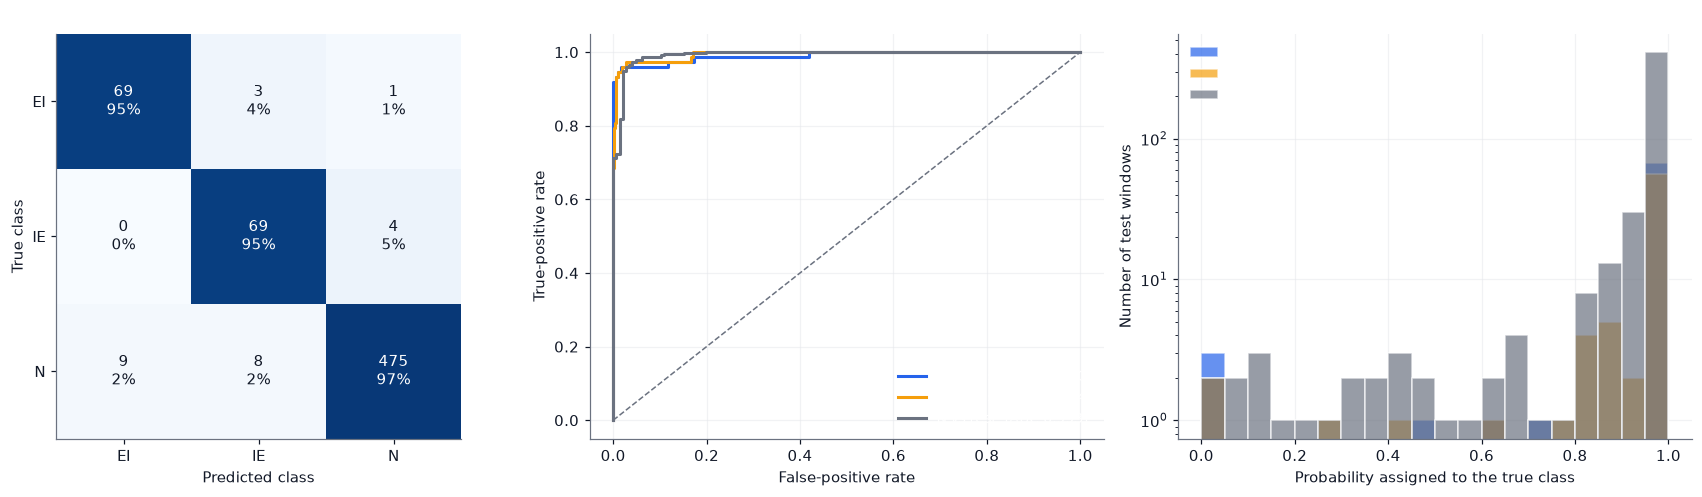

,test windows,precision,recall,F1
class,,,,
EI,73,0.885,"0.945 [0.867, 0.978]",0.914
IE,73,0.862,"0.945 [0.867, 0.978]",0.902
N,492,0.990,"0.965 [0.945, 0.978]",0.977


In [20]:
cm = confusion_matrix_np(y_te, pred_te)
row_pct = cm / cm.sum(axis=1, keepdims=True)

def roc_curve_np(y_true, score):
    y_true = np.asarray(y_true).astype(bool)
    order = np.argsort(-score, kind="stable"); s, yt = np.asarray(score)[order], y_true[order]
    tps, fps = np.cumsum(yt), np.cumsum(~yt)
    distinct = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]
    return np.r_[0.0, fps[distinct] / fps[-1]], np.r_[0.0, tps[distinct] / tps[-1]]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
im = axes[0].imshow(row_pct, cmap="Blues", vmin=0, vmax=1)
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(CLASS_NAMES); axes[0].set_yticks(range(3)); axes[0].set_yticklabels(CLASS_NAMES)
axes[0].set_xlabel("Predicted class"); axes[0].set_ylabel("True class"); axes[0].set_title("Test confusion matrix (count, % of true class)"); axes[0].grid(False)
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{cm[i, j]}\n{100 * row_pct[i, j]:.0f}%", ha="center", va="center", fontsize=10, color="white" if row_pct[i, j] > 0.55 else COLORS["dark"])

recall_rows = []
for i, c in enumerate(CLASS_NAMES):
    prec = cm[i, i] / max(cm[:, i].sum(), 1); rec = cm[i, i] / cm[i].sum(); f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    lo, hi = wilson_interval(int(cm[i, i]), int(cm[i].sum()))
    recall_rows.append({"class": c, "test windows": int(cm[i].sum()), "precision": round(prec, 3), "recall": f"{rec:.3f} [{lo:.3f}, {hi:.3f}]", "F1": round(f1, 3)})

for i, c in enumerate(CLASS_NAMES):
    fpr, tpr = roc_curve_np((y_te == i).astype(int), test_probs[:, i])
    axes[1].plot(fpr, tpr, color=CLASS_COLORS[c], label=f"{c} vs rest  (AUC {auc_rank((y_te == i).astype(int), test_probs[:, i]):.3f})")
axes[1].plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1)
axes[1].set_xlabel("False-positive rate"); axes[1].set_ylabel("True-positive rate"); axes[1].set_title("One-vs-rest ROC curves (ensemble)"); axes[1].legend(loc="lower right")

# Probability assigned to the true class: confident and correct, or uncertain?
true_class_prob = test_probs[np.arange(len(y_te)), y_te]
for i, c in enumerate(CLASS_NAMES):
    axes[2].hist(true_class_prob[y_te == i], bins=np.linspace(0, 1, 21), alpha=0.7, color=CLASS_COLORS[c], label=c, edgecolor="white")
axes[2].set_xlabel("Probability assigned to the true class"); axes[2].set_ylabel("Number of test windows"); axes[2].set_yscale("log")
axes[2].set_title("Confidence of the ensemble in the true class"); axes[2].legend()
finish(fig, "06_test_evaluation")
display(pd.DataFrame(recall_rows).set_index("class"))

In [21]:
# Error analysis: which windows are misclassified, and do they violate the canonical signals?
wrong = np.flatnonzero(pred_te != y_te)
err = pd.DataFrame({"name": names_te[wrong], "true": [CLASS_NAMES[i] for i in y_te[wrong]], "predicted": [CLASS_NAMES[i] for i in pred_te[wrong]],
                    "probability of prediction": test_probs[wrong, pred_te[wrong]].round(3), "central 4-mer (-2..+2)": [seq_te[i][28:32] for i in wrong]})
print(f"Misclassified test windows: {len(wrong)} of {len(y_te)}")
display(err.sort_values("probability of prediction", ascending=False).head(10).reset_index(drop=True))

ei_test = np.flatnonzero(y_te == 0); has_gt = np.array([seq_te[i][30:32] == "GT" for i in ei_test])
ie_test = np.flatnonzero(y_te == 1); has_ag = np.array([seq_te[i][28:30] == "AG" for i in ie_test])
print(f"\nEI windows WITH the canonical GT at +1,+2: {has_gt.sum()} -> recall {np.mean(pred_te[ei_test][has_gt] == 0):.3f}  |  WITHOUT it: {(~has_gt).sum()} -> recall {np.mean(pred_te[ei_test][~has_gt] == 0) if (~has_gt).any() else float('nan'):.3f}")
print(f"IE windows WITH the canonical AG at -2,-1: {has_ag.sum()} -> recall {np.mean(pred_te[ie_test][has_ag] == 1):.3f}  |  WITHOUT it: {(~has_ag).sum()} -> recall {np.mean(pred_te[ie_test][~has_ag] == 1) if (~has_ag).any() else float('nan'):.3f}")

Misclassified test windows: 25 of 638


,name,true,predicted,probability of prediction,central 4-mer (-2..+2)
0,HUMINCPPS-DONOR-2825,EI,N,0.987,GGGA
1,HUMTHY1A-ACCEPTOR-517,IE,N,0.984,AGTC
2,HUMTCBA-NEG-2161,N,IE,0.963,AGCT
3,HUMINCPPS-ACCEPTOR-2712,IE,N,0.958,CATG
4,HUMTCBYX-NEG-1,N,IE,0.929,AGCA
5,HUMIGHVQ-NEG-61,N,IE,0.896,AAGG
6,HUMTNFX-NEG-1681,N,EI,0.891,TGGT
7,HUMFERHX-NEG-481,N,IE,0.815,AGGT
8,HUMPRP0A-NEG-2161,N,EI,0.802,AGGT
9,ATRINS-NEG-841,N,EI,0.752,TGGT



EI windows WITH the canonical GT at +1,+2: 71 -> recall 0.972  |  WITHOUT it: 2 -> recall 0.000
IE windows WITH the canonical AG at -2,-1: 72 -> recall 0.958  |  WITHOUT it: 1 -> recall 0.000


## 12. How much does a random split overestimate performance?

We repeat the experiment with the **random stratified split**, keeping the architecture, the seeds, and the training protocol, and compare the test performance with that obtained on the grouped split. We also measure the reason directly: for each test window, the **identity with its nearest training window**,

$$
\text{identity}(x, x') = \frac{1}{L}\sum_{i=1}^{L}\mathbf{1}\{x_i = x'_i\}\quad\Longrightarrow\quad \max_{x' \in \text{training}}\ \text{identity}(x, x').
$$

Unrelated random DNA windows agree at about 25% of the positions by chance (and background windows here are close to uniform), so a high nearest-neighbour identity indicates *related* sequences. If the random split yields many near-identical neighbours, the test set is easier than genuinely new genes.

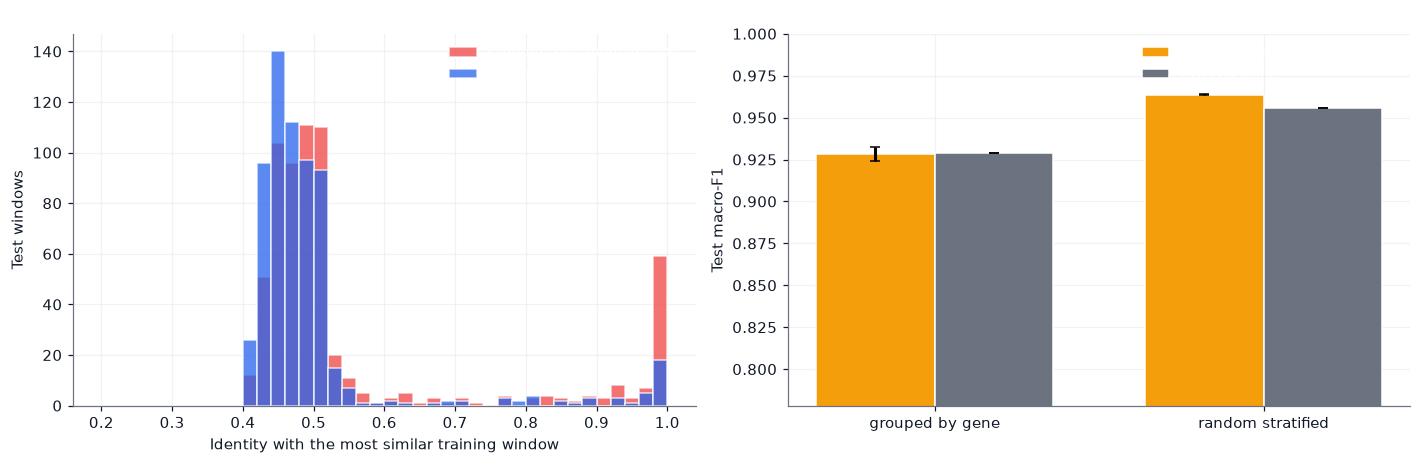

grouped by gene    | CNN + Flatten (position-aware): macro-F1 0.928 ± 0.004 | PWM macro-F1 0.929
random stratified  | CNN + Flatten (position-aware): macro-F1 0.964 ± 0.000 | PWM macro-F1 0.956


In [22]:
def nearest_identity(X_query, X_ref):
    """For every query window, the maximum fraction of identical positions with any reference window."""
    A, B = X_query.reshape(len(X_query), -1), X_ref.reshape(len(X_ref), -1)
    return (A @ B.T).max(axis=1) / L

tr_r, va_r, te_r = splits["random"]
random_arrays = {"X_tr": X_all[tr_r], "y_tr": y_all[tr_r], "X_va": X_all[va_r], "y_va": y_all[va_r], "X_te": X_all[te_r], "y_te": y_all[te_r]}

identity_grouped = nearest_identity(X_te, X_tr)
identity_random = nearest_identity(random_arrays["X_te"], random_arrays["X_tr"])

results_split = {}
builder = builders[selected]
for label, arrays in [("grouped by gene", grouped_arrays), ("random stratified", random_arrays)]:
    models_s = [train_seq_model(builder, arrays, s)[0] for s in seeds[:3]]
    accs = [metrics_from_probs(m.predict(arrays["X_te"], verbose=0), arrays["y_te"]) for m in models_s]
    pw_l, pw_p = fit_pwm(arrays["X_tr"], arrays["y_tr"])
    pwm_m = metrics_from_probs(softmax_np(pwm_log_posterior(arrays["X_te"], pw_l, pw_p)), arrays["y_te"])
    results_split[label] = {"nn_acc": [a["accuracy"] for a in accs], "nn_f1": [a["macro_f1"] for a in accs], "pwm_acc": pwm_m["accuracy"], "pwm_f1": pwm_m["macro_f1"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
bins = np.linspace(0.2, 1.0, 41)
axes[0].hist(identity_random, bins=bins, color=COLORS["red"], alpha=0.75, edgecolor="white", label=f"random split (median {np.median(identity_random):.2f})")
axes[0].hist(identity_grouped, bins=bins, color=COLORS["blue"], alpha=0.75, edgecolor="white", label=f"grouped split (median {np.median(identity_grouped):.2f})")
axes[0].set_xlabel("Identity with the most similar training window"); axes[0].set_ylabel("Test windows"); axes[0].set_title("Related sequences leak into the test set of a random split"); axes[0].legend()

labels_s = list(results_split)
x = np.arange(2); width = 0.36
for k, (key, title) in enumerate([("nn_f1", f"{selected}"), ("pwm_f1", "PWM baseline")]):
    vals = [np.mean(results_split[l][key]) if key == "nn_f1" else results_split[l][key] for l in labels_s]
    errs = [np.std(results_split[l][key]) if key == "nn_f1" else 0 for l in labels_s]
    axes[1].bar(x + (k - 0.5) * width, vals, width, yerr=errs, capsize=3, color=[COLORS["orange"], COLORS["gray"]][k], label=title, edgecolor="white")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels_s); axes[1].set_ylabel("Test macro-F1"); axes[1].set_title("Test performance under the two splits"); axes[1].legend()
lo = min(np.mean(results_split[l]["nn_f1"]) for l in labels_s)
axes[1].set_ylim(max(0, lo - 0.15), 1.0)
finish(fig, "07_random_vs_grouped")
for label in labels_s:
    r_ = results_split[label]
    print(f"{label:18s} | {selected}: macro-F1 {np.mean(r_['nn_f1']):.3f} \u00b1 {np.std(r_['nn_f1']):.3f} | PWM macro-F1 {r_['pwm_f1']:.3f}")

If the gene grouping is informative in your file (see the printout of Section 4.1), the random split shows **higher nearest-neighbour identities** and a **higher test score** than the grouped split. Note that the two test sets contain *different* windows, so this is a *comparison of two evaluation protocols*, not of the same model on the same data. The grouped result is the more honest estimate for *new genes*; the gap is the optimism of the random split. (If the names in your file do not group related genes, the two splits will look alike; this is a property of the benchmark, not a proof that no related sequences exist: homologous genes with *different* names also share sequence.)

## 13. What did the network learn?

### 13.1 Learned filters as motifs

The first convolution of the better of the two CNN architectures (by mean validation macro-F1) has 32 filters of width 7. By Section 8.2, each filter response is the sum of the kernel weights of the observed nucleotides, so a filter's kernel **is** a $7 \times 4$ PWM-like matrix: large positive entries mark the nucleotides that excite the filter. We show the filters whose class-average response profiles differ most between `EI` and `N`, together with their average response along the window.

Filters of: CNN + Flatten (position-aware)


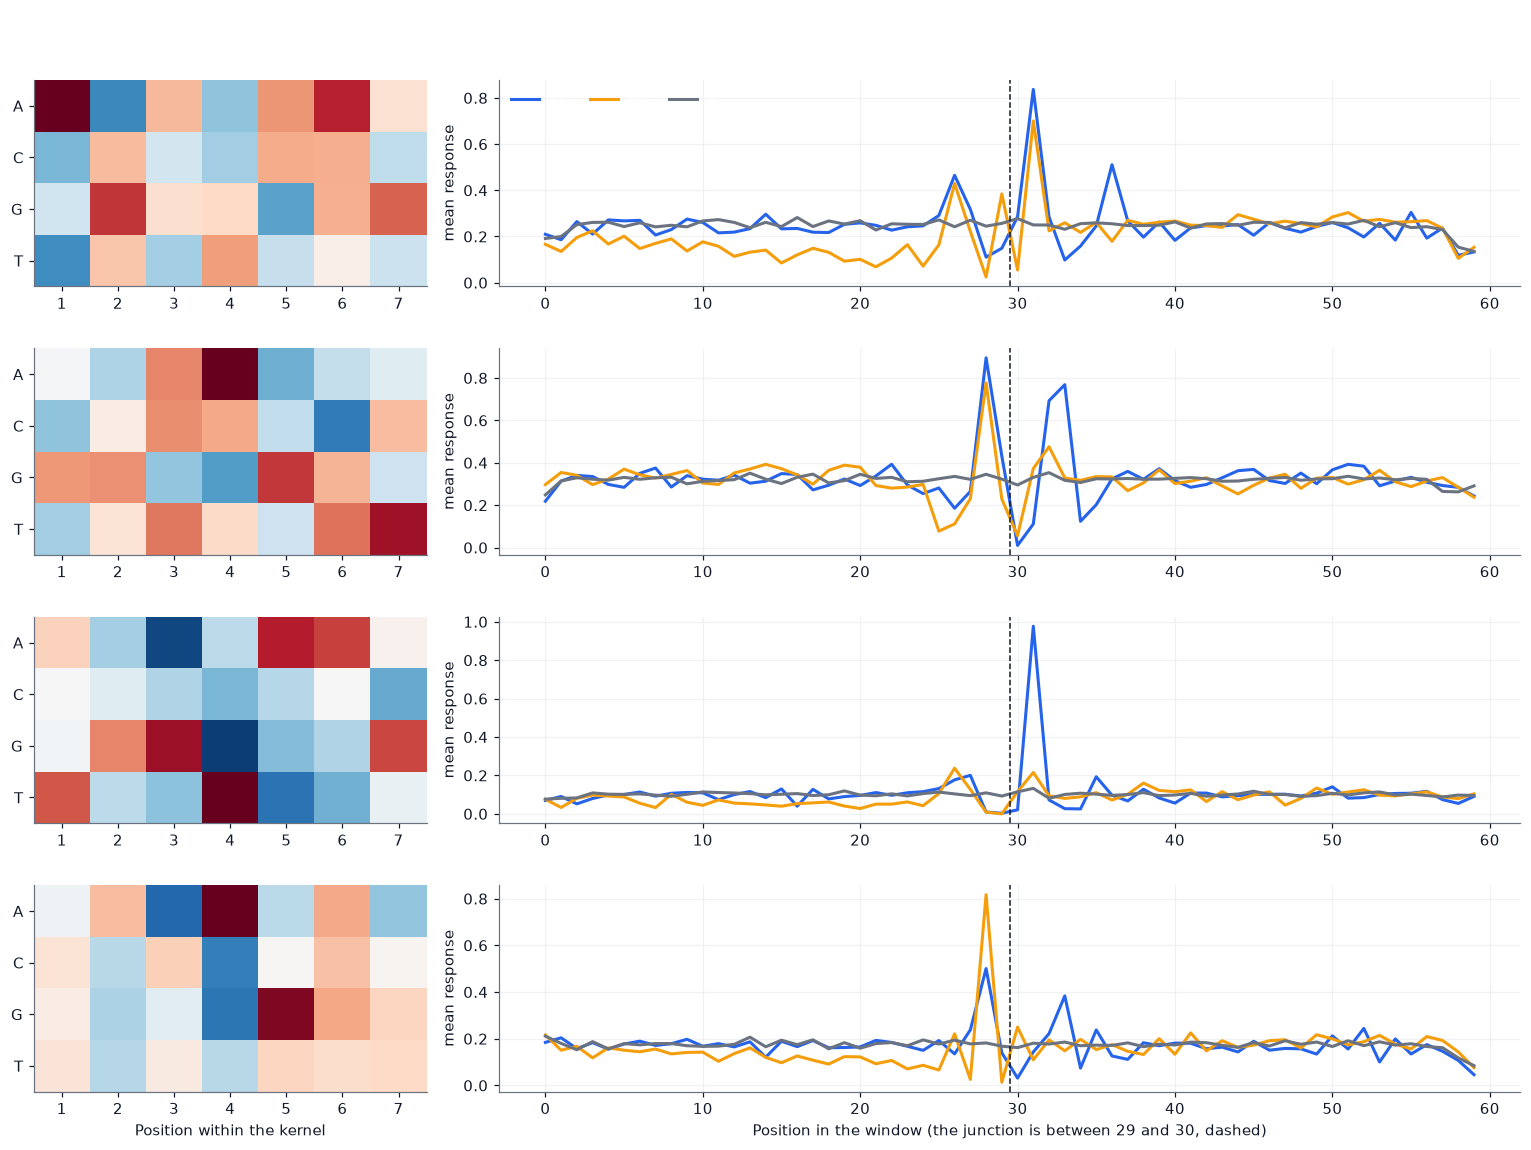

In [23]:
cnn_names = [n for n in builders if n.startswith("CNN")]
inspect_name = max(cnn_names, key=val_mean_f1.get)                                    # the better CNN (the MLP has no convolution filters)
model_inspect = trained[inspect_name][0]
print("Filters of:", inspect_name)
conv_1 = model_inspect.get_layer("conv_1")
kernels = conv_1.get_weights()[0]                                                    # (7, 4, 32)
conv_model = keras.Model(inputs=model_inspect.inputs, outputs=conv_1.output)
responses = keras.ops.convert_to_numpy(conv_model.predict(X_te, verbose=0))           # (N, 60, 32) after the ReLU
profile = {c: responses[y_te == i].mean(axis=0) for i, c in enumerate(CLASS_NAMES)}   # class-average response per position, (60, 32)
spread = np.max(np.abs(profile["EI"] - profile["N"]), axis=0) + np.max(np.abs(profile["IE"] - profile["N"]), axis=0)
top = np.argsort(-spread)[:4]

fig, axes = plt.subplots(len(top), 2, figsize=(14, 2.6 * len(top)), gridspec_kw={"width_ratios": [1, 2.6]})
for row, f in enumerate(top):
    kern = kernels[:, :, f].T                                                          # (4, 7): rows = nucleotides
    v = np.abs(kern).max()
    axes[row, 0].imshow(kern, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto"); axes[row, 0].grid(False)
    axes[row, 0].set_yticks(range(4)); axes[row, 0].set_yticklabels(list(BASES)); axes[row, 0].set_xticks(range(kern.shape[1])); axes[row, 0].set_xticklabels(range(1, kern.shape[1] + 1))
    consensus = "".join(BASES[i] for i in kern.argmax(axis=0))
    axes[row, 0].set_title(f"filter {f}: kernel (consensus {consensus})", fontsize=10)
    for c in CLASS_NAMES:
        axes[row, 1].plot(np.arange(L), profile[c][:, f], color=CLASS_COLORS[c], label=c)
    axes[row, 1].axvline(29.5, color=COLORS["dark"], linestyle="--", linewidth=1); axes[row, 1].set_ylabel("mean response")
    if row == 0: axes[row, 1].legend(ncol=3, loc="upper left")
axes[-1, 1].set_xlabel("Position in the window (the junction is between 29 and 30, dashed)"); axes[-1, 0].set_xlabel("Position within the kernel")
fig.suptitle("The four first-layer filters whose responses differ most between classes (left: kernel, right: average response along the window)", fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.0)
finish(fig, "08_learned_filters")

Look for filters whose kernels resemble the canonical signals (a G followed by a T for donors, an A followed by a G, or pyrimidine-rich kernels, for acceptors) and whose response profile peaks **near the junction** for the matching class. Many filters of a small network remain hard to interpret individually (they may encode partial or redundant patterns that only make sense in combination), so we complement this with a more direct, model-agnostic analysis.

### 13.2 In-silico mutagenesis

A direct way to ask *which positions matter to the model*: for a window $x$ of class $c$, replace the nucleotide at position $i$ by each of the three alternatives $b'$, and record the change in the predicted probability of the true class,

$$
\Delta_{i,b'}(x) = \hat{p}_c(x^{(i \to b')}) - \hat{p}_c(x), \qquad
\text{importance}(i) = \mathbb{E}_{x \in c}\Big[\tfrac{1}{3}\sum_{b' \neq x_i}\big|\Delta_{i,b'}(x)\big|\Big].
$$

The importance profile of a model that has learned splice-site biology should **peak at the canonical positions**: $+1, +2$ (the GT of the donor) for `EI`, and $-2, -1$ (the AG of the acceptor) for `IE`, with moderate importance in the flanking consensus. This needs no gradients, only predictions of the mutated sequences. We use the ensemble and up to 80 test windows per class.

Done in 15 s


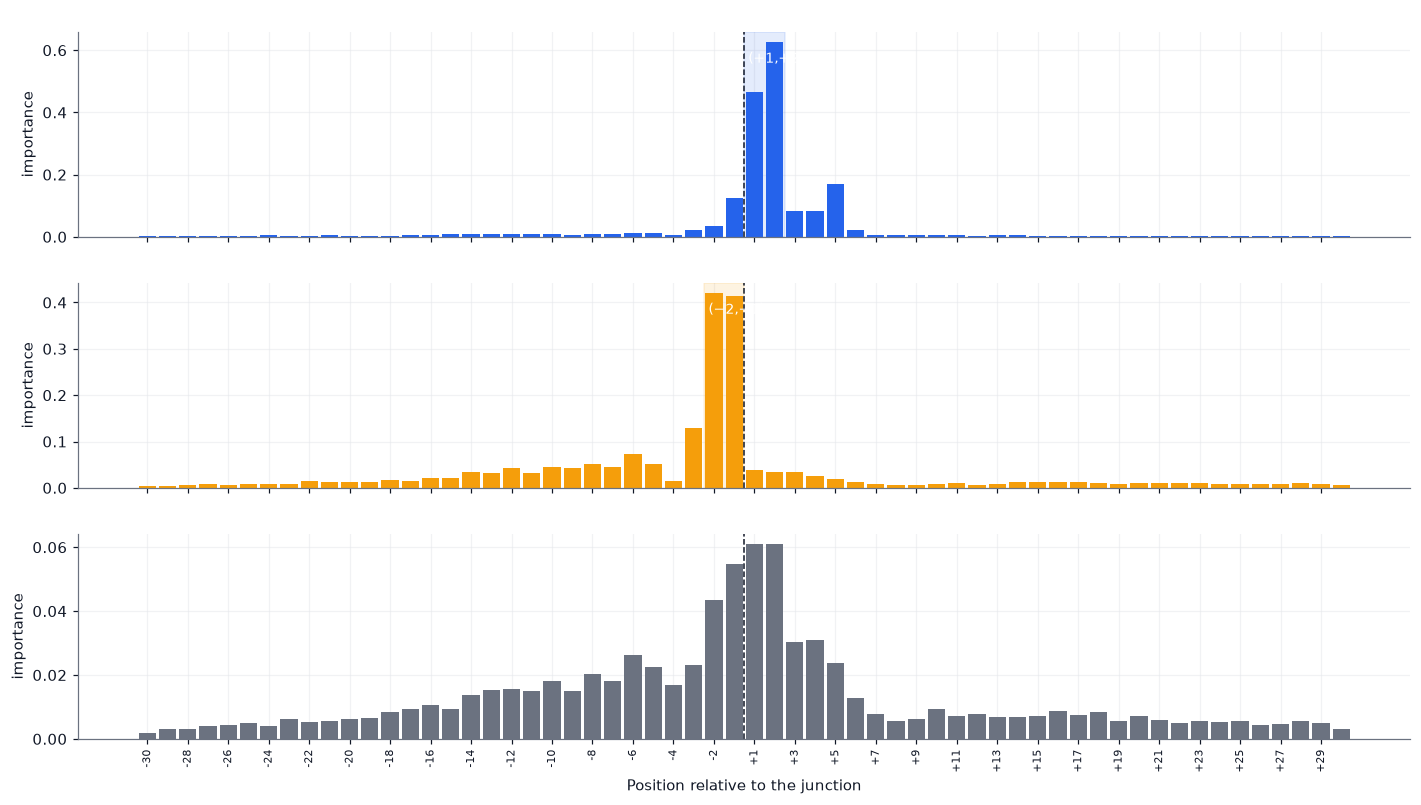

Class EI: mean importance at the canonical dinucleotide 0.546 | at all other positions 0.014 | ratio 40.2x
Class IE: mean importance at the canonical dinucleotide 0.418 | at all other positions 0.020 | ratio 20.7x


In [24]:
def mutagenesis_importance(models, sequences, labels_idx, max_windows=80, seed=0):
    r = np.random.default_rng(seed)
    out = {}
    for cls, c in enumerate(CLASS_NAMES):
        idx = np.flatnonzero(labels_idx == cls)
        idx = r.choice(idx, size=min(max_windows, len(idx)), replace=False)
        mutants, owner, position = [], [], []
        base_windows = np.stack([one_hot_encode([sequences[i]])[0] for i in idx])
        for w, i in enumerate(idx):
            seq = sequences[i]
            for pos in range(L):
                if seq[pos] not in BASES:
                    continue
                for alt in BASES:
                    if alt == seq[pos]:
                        continue
                    mutant = base_windows[w].copy(); mutant[pos] = SOFT_CODES[alt]
                    mutants.append(mutant); owner.append(w); position.append(pos)
        base_p = ensemble_predict(models, base_windows)[:, cls]
        mut_p = ensemble_predict(models, np.stack(mutants))[:, cls]
        deltas = np.abs(mut_p - base_p[owner])
        imp = np.zeros(L); cnt = np.zeros(L)
        np.add.at(imp, position, deltas); np.add.at(cnt, position, 1)
        out[c] = imp / np.maximum(cnt, 1)
    return out

t0 = time.time()
importance = mutagenesis_importance(ens_models, seq_te, y_te)
print(f"Done in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(3, 1, figsize=(13, 7.4), sharex=True)
for ax, c in zip(axes, CLASS_NAMES):
    ax.bar(np.arange(L), importance[c], color=CLASS_COLORS[c], width=0.85)
    ax.axvline(29.5, color=COLORS["dark"], linestyle="--", linewidth=1)
    ax.set_ylabel("importance"); ax.set_title(f"Class {c}: mean change of the true-class probability after a point mutation", fontsize=10.5)
if True:
    axes[0].axvspan(29.5, 31.5, color=COLORS["blue"], alpha=0.12); axes[0].annotate("GT (+1,+2)", (30.5, axes[0].get_ylim()[1] * 0.85), ha="center", fontsize=9)
    axes[1].axvspan(27.5, 29.5, color=COLORS["orange"], alpha=0.12); axes[1].annotate("AG (\u22122,\u22121)", (28.5, axes[1].get_ylim()[1] * 0.85), ha="center", fontsize=9)
axes[-1].set_xticks(range(0, L, 2)); axes[-1].set_xticklabels(pos_labels[::2], rotation=90, fontsize=7.5)
axes[-1].set_xlabel("Position relative to the junction")
finish(fig, "09_mutagenesis")
for c, sl in [("EI", slice(30, 32)), ("IE", slice(28, 30))]:
    inside, outside = importance[c][sl].mean(), np.delete(importance[c], np.arange(sl.start, sl.stop)).mean()
    print(f"Class {c}: mean importance at the canonical dinucleotide {inside:.3f} | at all other positions {outside:.3f} | ratio {inside / max(outside, 1e-9):.1f}x")

Interpretation: a clear peak at the canonical dinucleotide (and elevated importance in the immediate neighbourhood) shows that the network relies on **the same signals that molecular biologists identified**, which is reassuring: it is not exploiting an artefact. The importance of the `N` class is typically low and spread out (no single position decides "not a junction"). Remember the limits of this analysis: it measures the effect of **single** mutations on the **average** window; interactions between positions, and the behaviour for windows unlike those of the dataset, are not covered. Importance is not causation in the cell: it describes the *model*, not the splicing machinery.

## 14. Interpretation and limitations

**What the results can support.** A small CNN (and, in this dataset, even a PWM baseline) recognizes splice-junction windows with high accuracy; position-aware architectures use the information at the junction; and in-silico mutagenesis shows that the model relies on the canonical GT and AG signals.

**What they do not support.**

1. **Not a genome-scanning result.** The task here is to classify *pre-centred* windows. In a real genome, junctions are extremely rare among all positions, so the precision of a classifier with a small false-positive rate drops dramatically (Notebook 07: positive predictive value and prevalence). Real splice-site predictors are evaluated with precision–recall curves on whole genes.
2. **Easy negatives.** The `N` windows come from regions without splice sites; real hard negatives (cryptic splice sites, GT–AG pairs inside exons) are rarer here than in genomes.
3. **Related sequences.** Even with the grouped split, homologous genes can share sequence under different names; an exact-sequence or similarity-based grouping would be stricter. The grouping uses the instance names of an old dataset and may not be perfect.
4. **Size and age.** 3,190 windows from GenBank release 64.1 (1991) are few and not representative of all splicing (alternative splicing, non-canonical introns, other species).
5. **Strand.** The windows are given in the gene's 5′→3′ direction. Reverse-complement augmentation, standard in genomics for strand-agnostic problems (for example transcription-factor binding), would **not** be label-preserving here: the reverse complement of a donor is not a donor.
6. **One benchmark split and a few seeds.** Intervals are wide for the rare per-class metrics (about 150 test windows per splice class).

## 15. Saving the models with their metadata, and using them on a new sequence

In [25]:
saved = []
for i, m in enumerate(ens_models):
    path = os.path.join(ARTIFACT_DIR, f"splice_{selected.split(' ')[0].lower()}_{selected.replace(' ', '_').replace('+', 'plus')}_seed{seeds[i]}.keras")
    m.save(path); saved.append(os.path.basename(path))
np.savez(os.path.join(ARTIFACT_DIR, "splice_pwm_baseline.npz"), log_p=pwm_logp, log_prior=pwm_log_prior)

meta = {
    "dataset": "UCI Molecular Biology (Splice-junction Gene Sequences), DOI 10.24432/C5M888, CC BY 4.0",
    "window": "60 nucleotides, positions -30..-1,+1..+30; junction between index 29 and 30 (0-based)",
    "classes": CLASS_NAMES, "encoding": "one-hot ACGT; ambiguity codes D, N, S, R as soft one-hot vectors",
    "split": {"primary": "grouped by gene group (text before the first hyphen of the instance name)", "seed": SEED,
              "train": int(len(tr_g)), "validation": int(len(va_g)), "test": int(len(te_g))},
    "selected_architecture": selected, "selection_rule": "highest mean validation macro-F1 over seeds", "ensemble_seeds": seeds, "files": saved,
    "validation_macro_f1_mean": {k: float(v) for k, v in val_mean_f1.items()},
    "test_ensemble": {k: float(v) for k, v in ens_metrics.items()}, "test_ensemble_95ci": {k: [float(x) for x in v] for k, v in ens_ci.items()},
    "test_pwm_baseline": {k: float(v) for k, v in pwm_metrics.items()},
    "versions": {"python": sys.version.split()[0], "keras": keras.__version__, "backend": keras.backend.backend(), "numpy": np.__version__},
}
with open(os.path.join(ARTIFACT_DIR, "splice_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

def predict_sequence(sequence, models=ens_models):
    """Class probabilities of one 60-nucleotide window (letters A, C, G, T, and the ambiguity codes D, N, S, R)."""
    sequence = sequence.strip().upper()
    if len(sequence) != L or any(ch not in SOFT_CODES for ch in sequence):
        raise ValueError(f"A window must have exactly {L} nucleotides from {sorted(SOFT_CODES)}.")
    probs = ensemble_predict(models, one_hot_encode([sequence]))[0]
    return {c: round(float(p), 3) for c, p in zip(CLASS_NAMES, probs)}

example = seq_te[int(np.flatnonzero(y_te == 0)[0])]
print("A donor-site window from the test set:", example)
print("Predicted probabilities:", predict_sequence(example))
shuffled = "".join(np.random.default_rng(3).permutation(list(example)))
print("The same nucleotides in random order:  ", shuffled, "->", predict_sequence(shuffled))

A donor-site window from the test set: TGGGGGTGCCTGGGCTGCAGAAGTGATCAGGTAACTGAGCTCCTGGGACGTTAGGGCTGG
Predicted probabilities: {'EI': 0.999, 'IE': 0.0, 'N': 0.001}
The same nucleotides in random order:   GTGGAGCCTGACGTGGGTTTTAGAGGGCGGAAGTAGATACTTCGCCTATCGGCGGGGGGC -> {'EI': 0.044, 'IE': 0.001, 'N': 0.956}


## 16. What did we learn?

1. **Biology:** splice junctions have the canonical signals GT (donor, `EI`, at $+1,+2$) and AG (acceptor, `IE`, at $-2,-1$, after a pyrimidine-rich tract). Logos and position-frequency matrices make these visible, but the dinucleotides alone are weak signals (they occur in many background windows).
2. **Encoding:** one-hot vectors avoid inventing an order between nucleotides; ambiguity codes become soft vectors; an embedding is a one-hot layer.
3. **PWM = naive Bayes = a linear scan:** a position weight matrix is a position-specific naive Bayes classifier, and **scanning a PWM along a sequence is a 1D convolution** (verified exactly): a learned filter on one-hot DNA is a motif detector.
4. **1D convolution:** $L_{out} = \lfloor (L + 2p - k)/s \rfloor + 1$, $(kC_{in}+1)F$ parameters, and a backward pass whose kernel gradient adds the upstream gradient to the rows of the observed nucleotides; our NumPy implementation agrees with Keras and with a numerical gradient check.
5. **Pooling over positions:** global max pooling detects motif *presence* but discards *position*; for splice junctions position matters, so position-aware designs are preferable (and a PWM at its home position discriminates better than its maximum over all positions).
6. **Evaluation:** multi-seed comparisons, an ensemble, confusion matrix, per-class metrics, one-vs-rest AUC, bootstrap and Wilson intervals, and a paired test against the PWM baseline.
7. **Leakage between related sequences:** a random split places near-identical windows in training and test; grouping by gene gives a more honest estimate (the nearest-neighbour identity quantifies the leak).
8. **Interpretation:** learned filters and **in-silico mutagenesis** can be checked against known biology (importance peaking at GT and AG); they describe the model, not the cell.
9. **Limits:** pre-centred windows, easy negatives, old and small data, related sequences, strand.

### Key terms

| Term | Meaning |
|---|---|
| Exon, intron | Retained / spliced-out part of a pre-mRNA |
| Donor (EI), acceptor (IE) | Exon→intron / intron→exon boundary |
| PFM, PWM | Position frequency matrix / position weight matrix (log-odds) |
| Information content | $2 + \sum_b p\log_2 p$ bits at a position |
| Sequence logo | Letters stacked with height $p\cdot IC$ |
| One-hot, soft one-hot | Indicator vector / probability vector for an ambiguity code |
| 1D convolution | Sliding weighted sum along a sequence |
| Global max pooling | Maximum over positions per filter (position-independent) |
| Ensemble | Average of the predictions of several networks |
| Grouped split | Related samples (here: genes) kept in one partition |
| In-silico mutagenesis | Effect of every point mutation on the model's output |

## 17. Exercises

### A. Mathematics

1. Compute the information content of a position with probabilities $(0.7, 0.1, 0.1, 0.1)$ for $(A, C, G, T)$. What is the maximum, and for which distribution?
2. Show that the PWM (naive Bayes) classifier is a **linear** function of the one-hot features: write $\log P(c \mid x)$ as $\sum_{i,b} X_{i,b}\,w_{c,i,b} + \text{constant}$ and identify $w$. How many parameters does it have for $L = 60$ and 3 classes?
3. A convolution on a one-hot sequence has $k = 9$, $F = 64$. Compute the number of parameters, the output length for $L = 60$ with `"same"` and with `"valid"` padding, and the number of MACs.
4. Using the formula of Section 8.2, show that if the kernel rows are $K_{m,b} = \log\frac{p_c(m,b)}{p_{\text{bg}}(b)}$, then $Y_{i} = \log\frac{P(x_{i:i+k}\mid c)}{P(x_{i:i+k}\mid \text{background})}$.
5. The **reverse complement** of a DNA window reverses the order and swaps $A \leftrightarrow T$, $C \leftrightarrow G$. Write it as an operation on the one-hot matrix $X \in \mathbb{R}^{L \times 4}$ (a flip of the position axis and a permutation matrix on the channel axis). What condition on a kernel $K$ makes a convolution **equivariant** to the reverse complement?
6. Show that `GlobalMaxPooling1D` after a `"valid"` convolution is **invariant** to circular shifts of the input if the sequence is treated as circular, but not for a window of fixed boundaries, and explain what this means for the splice problem.
7. How many single point mutations does a window of 60 nucleotides have? How many forward passes does in-silico mutagenesis of 80 windows need, and how would you reduce the cost?
8. For the one-hot input, derive the gradient of the loss with respect to the kernel entry $K_{m,b,f}$ as a sum over the positions where the $k$-mer has nucleotide $b$ at offset $m$.

### B. Programming

1. Add **reverse-complement augmentation** to the training set and show (with the validation and test macro-F1 over several seeds) that it hurts, for the reason of Section 14.
2. Replace the first convolution's `"same"` padding by `"valid"` and adapt the rest. Does the accuracy change? What happens to the alignment of the positions?
3. Try other filter widths (3, 5, 11, 15) and numbers of filters (8, 16, 64) and plot the validation macro-F1 against the number of parameters.
4. Add a **learned embedding** (`Embedding` on integer-coded sequences) instead of the one-hot input and verify that the results are similar.
5. Build a **$k$-mer baseline** (counts of all 3-mers, 64 features) with a Dense softmax layer and compare it with the PWM and the CNN.
6. Implement a **grouped $k$-fold cross-validation** by gene group and report the mean ± SD of the macro-F1 for the PWM, the MLP and the position-aware CNN.
7. Compute a **saliency map** with gradients (`tf.GradientTape`) and compare it with in-silico mutagenesis for the same windows.
8. Replace the PWM log-odds of Section 8.4 by the learned kernel of the best filter of Section 13.1 and repeat the "home position against maximum" comparison.
9. Evaluate the **calibration** of the ensemble (reliability diagram, ECE; Notebook 07). Does averaging the networks improve it?

### C. Research thinking

1. If you scanned a gene of 20,000 positions that contains 10 donor sites with this classifier, and its false-positive rate on background positions is 1%, how many false donors do you expect? What would the precision be? What does this say about the benchmark?
2. Why would a **global max pooling** architecture be the right choice for predicting whether a transcription factor binds somewhere in a 1,000-nucleotide promoter, but not for this problem?
3. A model predicts that a point mutation at position $+2$ of a donor site destroys splicing. Which experiments would you run to test this prediction, and what would convince you that the model has learned a causal mechanism and not a correlation?
4. How would you design a train/validation/test split to evaluate a splice-site model for **a species that is not in the training data**?

## 18. Further exploration and references

### Dataset

- Noordewier, M. O., Towell, G. G., and Shavlik, J. W. (1991). Training knowledge-based neural networks to recognize genes in DNA sequences. *Advances in Neural Information Processing Systems 3*.
- *Molecular Biology (Splice-junction Gene Sequences)* [Dataset] (1991). UCI Machine Learning Repository. <https://doi.org/10.24432/C5M888> (CC BY 4.0). Donors: G. Towell, M. Noordewier, and J. Shavlik.
- Towell, G. G. and Shavlik, J. W. (1994). Knowledge-based artificial neural networks. *Artificial Intelligence*, 70, 119–165.

### Sequence motifs and deep learning for genomics

- Schneider, T. D. and Stephens, R. M. (1990). Sequence logos: a new way to display consensus sequences. *Nucleic Acids Research*, 18, 6097–6100.
- Stormo, G. D. (2000). DNA binding sites: representation and discovery. *Bioinformatics*, 16, 16–23.
- Alipanahi, B., Delong, A., Weirauch, M. T., and Frey, B. J. (2015). Predicting the sequence specificities of DNA- and RNA-binding proteins by deep learning. *Nature Biotechnology*, 33, 831–838.
- Zhou, J. and Troyanskaya, O. G. (2015). Predicting effects of noncoding variants with deep learning-based sequence model. *Nature Methods*, 12, 931–934.
- Jaganathan, K., *et al.* (2019). Predicting splicing from primary sequence with deep learning. *Cell*, 176, 535–548.
- Koo, P. K. and Eddy, S. R. (2019). Representation learning of genomic sequence motifs with convolutional neural networks. *PLoS Computational Biology*, 15(12), e1007560.
- Eraslan, G., Avsec, Ž., Gagneur, J., and Theis, F. J. (2019). Deep learning: new computational modelling techniques for genomics. *Nature Reviews Genetics*, 20, 389–403.

### Keras documentation

- [Convolution layers (`Conv1D`)](https://keras.io/api/layers/convolution_layers/convolution1d/) and [pooling layers](https://keras.io/api/layers/pooling_layers/) (`MaxPooling1D`, `GlobalMaxPooling1D`)
- [`Embedding`](https://keras.io/api/layers/core_layers/embedding/)

### Suggested reading

- Goodfellow, Bengio, and Courville — *Deep Learning*: chapter 9 (convolutional networks) and chapter 10 (sequence modelling).
- Chollet — *Deep Learning with Python*: the section on 1D convnets for sequence processing.
- Durbin, Eddy, Krogh, and Mitchison — *Biological Sequence Analysis* (PWMs, profile models, and probabilistic modelling of sequences).

---

## Next notebook

**11 — Autoencoders for Biological Data**

We return to the gene-expression data and turn to **unsupervised learning**: encoder and decoder networks, the latent space, reconstruction loss, and dimension reduction of 20,000-dimensional expression profiles into a handful of numbers — with links to PCA (an autoencoder with linear layers) and with the evaluation habits of Notebook 07.